# CMiO SC-PaCMAP results

This compact notebook keeps the benchmark contract visible: full-population CMiO data, six active unsupervised embeddings, K-means at the known class count $K=7$, and evaluation-only deposit labels. Thirty algorithm seeds are retained in memory to show seed ranges rather than a single lucky run.

The primary views are the three evaluation trajectories, the spatial-feature trade-off cloud, a 10-seed lambda-cap sensitivity check, and a 10-seed cross-group continuity check. No result files are written.

SC-PaCMAP benchmark runs use `SCPaCMAPConfig(max_target_share=1.0)`: no extra clipping below the natural bound of 1. 

**Paper figures:** all plots use consistent sans-serif typography and 600-dpi inline PNG output, with one figure title and compact categorical legends and slim continuous color scales. Copy images directly from their output. Full-width figures are 7.1 inches wide; the lambda figure is 3.5 inches wide. Plotting cells are separate from computation so they can be rerun with results already in memory. No images are exported.


**Experiment switch:** `INCLUDE_REPLACEMENT = False` disables the replacement variant in fitting, evaluation, and plots. Set it to `True` in setup to restore the ablation. Figure labels use ?SC-PaCMAP? for the full-graph method. Rerun setup and computation after changing the dataset or switch; existing in-memory results may otherwise describe the previous experiment.


In [1]:
from __future__ import annotations
from IPython.display import display
import importlib, os, sys, time
from pathlib import Path

# Keep an already imported kernel's Numba pool size; use one active thread.
# On a fresh kernel, configure the pool before numerical imports.
os.environ['NUMBA_NUM_THREADS'] = str(sys.modules['numba'].config.NUMBA_NUM_THREADS) if 'numba' in sys.modules else '1'
import matplotlib.pyplot as plt
import numba, numpy as np, pandas as pd, seaborn as sns
numba.set_num_threads(1)
import pacmap, umap
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

def find_root(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file(): return candidate
        nested = candidate / 'sc-pacmap-reproducibility'
        if (nested / 'code' / 'sc_pacmap' / 'sc_pacmap.py').is_file(): return nested
    raise FileNotFoundError('Repository root not found')

ROOT = find_root()
for folder in (ROOT / 'code' / 'sc_pacmap', ROOT / 'code' / 'spasne'):
    sys.path.insert(0, str(folder)) if str(folder) not in sys.path else None
from sc_pacmap import PaCMAPSettings, SCPaCMAPConfig, run_legacy_sc_pacmap, run_sc_pacmap
sc_config = SCPaCMAPConfig(max_target_share=1.0)  # No extra clipping below 1.
from spasne_adapter import python_spasne
# Keep LocalMAP's Numba resampling reproducible without an external helper file.
import importlib
from contextlib import contextmanager

@numba.njit
def seed_localmap_rng(seed):
    np.random.seed(seed)

@contextmanager
def localmap_seed(seed):
    core = importlib.import_module('pacmap.pacmap')
    original_resample = core.sample_FP_pair_nearby
    call_index = 0
    def seeded_resample(*args, **kwargs):
        nonlocal call_index
        seed_localmap_rng(seed + call_index)
        call_index += 1
        return original_resample(*args, **kwargs)
    seed_localmap_rng(seed)
    core.sample_FP_pair_nearby = seeded_resample
    try:
        yield
    finally:
        core.sample_FP_pair_nearby = original_resample

SEEDS = tuple(range(30))
SENSITIVITY_SEEDS = tuple(range(10))
N_NEIGHBORS, N_COMPONENTS, K_REFERENCE = 10, 2, 7
FEATURES = ['Y_PPM','V_PPM','LA_PPM','U_PPM','SR_PPM','SN_PPM','RB_PPM','TH_PPM','CS_PPM','CE_PPM','NB_PPM','GA_PPM','W_PPM','HF_PPM','TA_PPM','ZR_PPM','CR_PPM','PR_PPM','ND_PPM','ER_PPM','EU_PPM','SM_PPM','YB_PPM','TB_PPM','HO_PPM','GD_PPM','DY_PPM','LU_PPM','BA_PPM','SIO2_WT_PERCENT','TIO2_WT_PERCENT','NA2O_WT_PERCENT','K2O_WT_PERCENT','AL2O3_WT_PERCENT','TM_PPM']
data = pd.read_csv(ROOT / 'data' / 'processed' / 'cmio_sc_pacmap_ready.csv')
coords = data[['x','y','z']].to_numpy(float)
truth = data['label_id'].to_numpy(int)
features = StandardScaler().fit_transform(data[FEATURES]).astype(np.float32)
xyz = StandardScaler().fit_transform(coords)
features_xyz = np.column_stack([features, xyz])
tss = float(np.sum((features - features.mean(0, keepdims=True)) ** 2))
spatial_neighbors = NearestNeighbors(n_neighbors=N_NEIGHBORS + 1, n_jobs=1).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]
settings_base = dict(n_components=2, n_neighbors=N_NEIGHBORS, mn_ratio=.5, fp_ratio=2., learning_rate=1., num_iters=(100,100,250), knn_backend='faiss', verbose=False)
ALL_METHODS = ['UMAP + XYZ','PaCMAP + XYZ','LocalMAP + XYZ','PaCMAP feature-only','SC-PaCMAP replacement','SC-PaCMAP full graph','SpaSNE']
INCLUDE_REPLACEMENT = False  # Enable only when running the replacement ablation.
METHODS = [m for m in ALL_METHODS if INCLUDE_REPLACEMENT or m != "SC-PaCMAP replacement"]
print(f'{len(data)} samples | {len(FEATURES)} features | {data.group_id.nunique()} groups | K={K_REFERENCE}')
K_VALUES = range(2, 11)
MARKERS = dict(zip(ALL_METHODS, ['o', '^', 'v', 'P', 'h', '*', 'X']))
NEIGHBOR_VALUES = (10, 15, 20)  # Embedding neighborhoods in stability/cloud sections only
DATASET_TITLE = 'CMiO'


# Publication defaults: full-paper-width figures, 600-dpi inline PNG, no exports.
from matplotlib_inline.backend_inline import set_matplotlib_formats
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
set_matplotlib_formats('png')
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'mathtext.fontset': 'dejavusans',
    'font.size': 8, 'axes.titlesize': 8, 'figure.titlesize': 10, 'figure.titleweight': 'normal',
    'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'legend.title_fontsize': 7,
    'figure.dpi': 600, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#444444', 'axes.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'grid.color': '#E4E4E4', 'grid.linewidth': .45,
    'xtick.major.size': 3, 'ytick.major.size': 3,
    'xtick.major.width': .6, 'ytick.major.width': .6,
    'lines.linewidth': 1.1, 'lines.markersize': 3,
    'legend.frameon': False, 'figure.constrained_layout.h_pad': .06,
    'figure.constrained_layout.w_pad': .06,
})
# Stable named mappings keep colors unchanged when the ablation is toggled.
COLORS = dict(zip(ALL_METHODS, ['#4477AA', '#66AABB', '#228833', '#AA8855', '#AA3377', '#BB4455', '#666666']))
METHOD_LABELS = {m: ('SC-PaCMAP' if m == 'SC-PaCMAP full graph' else m) for m in ALL_METHODS}
# Distinct, muted categorical colors; no pale alternating class pairs.
CLASS_IDS = np.unique(truth)
CLASS_PALETTE = ['#4477AA', '#CC6677', '#228833', '#AA3377', '#66AABB',
                 '#BB9944', '#554488', '#44AA99', '#882255', '#777777',
                 '#336666', '#AA7744', '#667733', '#AA88AA', '#446688']
CLASS_CMAP = ListedColormap(CLASS_PALETTE[:len(CLASS_IDS)])
CLASS_NORM = BoundaryNorm(np.arange(len(CLASS_IDS) + 1) - .5, len(CLASS_IDS))
CLASS_INDEX = np.searchsorted(CLASS_IDS, truth)
if 'LABEL_deposit_group' in data:
    names = data.drop_duplicates('label_id').set_index('label_id')['LABEL_deposit_group']
    CLASS_LABELS = [str(names.loc[label]) for label in CLASS_IDS]
elif 'label_lithology' in data:
    names = data.drop_duplicates('label_id').set_index('label_id')['label_lithology']
    CLASS_LABELS = [str(names.loc[label]).split(' - ')[0].strip() for label in CLASS_IDS]
else:
    CLASS_LABELS = [f'Facies {chr(65 + i)}' for i in range(len(CLASS_IDS))]

def class_legend(fig, ax=None):
    handles = [Line2D([], [], marker='o', linestyle='None',
                      markerfacecolor=CLASS_PALETTE[i], markeredgecolor='none',
                      markersize=4, label=label) for i, label in enumerate(CLASS_LABELS)]
    if ax is not None:
        return ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, -.30),
                         ncol=2, handletextpad=.3, columnspacing=.8, borderaxespad=0)
    columns = 5 if len(handles) > 9 else (4 if len(handles) <= 4 else 3)
    return fig.legend(handles=handles, loc='outside lower center', ncol=columns,
                      handletextpad=.35, columnspacing=1.3, labelspacing=.45)

def paper_show(fig):
    # One high-resolution copyable image, without creating files on disk.
    display(fig)
    plt.close(fig)


c:\Users\weihong\Desktop\SC-PACMAP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1551 samples | 35 features | 38 groups | K=7


### Reference fit and evaluation helpers

Fit the reference embeddings needed for graph diagnostics; group IDs are used only for evaluation.


In [2]:
def fit_embeddings(seed, feature_values=features, coordinate_values=coords, *,
                   n_neighbors=N_NEIGHBORS, spasne_embedding=None):
    numba.set_num_threads(1)
    features_with_coordinates = np.column_stack([feature_values, StandardScaler().fit_transform(coordinate_values)])
    settings = PaCMAPSettings(random_state=seed, **{**settings_base, 'n_neighbors': n_neighbors})
    pacmap_args = {'n_components':2, 'n_neighbors':n_neighbors, 'MN_ratio':.5, 'FP_ratio':2., 'distance':'euclidean', 'lr':1., 'num_iters':(100,100,250), 'apply_pca':True, 'random_state':seed, 'save_tree':False, 'knn_backend':'faiss'}
    out = {}
    out['UMAP + XYZ'] = umap.UMAP(n_neighbors=n_neighbors, n_components=2, metric='euclidean', learning_rate=1., random_state=seed, n_jobs=1).fit_transform(features_with_coordinates)
    out['PaCMAP + XYZ'] = pacmap.PaCMAP(**pacmap_args).fit_transform(features_with_coordinates, init='pca', save_pairs=False)
    with localmap_seed(seed):
        out['LocalMAP + XYZ'] = pacmap.LocalMAP(**{**pacmap_args, 'low_dist_thres':10}).fit_transform(np.ascontiguousarray(features_with_coordinates, dtype=np.float64), init='pca', save_pairs=False)
    out['PaCMAP feature-only'] = pacmap.PaCMAP(**pacmap_args).fit_transform(feature_values, init='pca', save_pairs=False)
    if INCLUDE_REPLACEMENT:
        replacement, _ = run_legacy_sc_pacmap(feature_values, coordinate_values, settings); out['SC-PaCMAP replacement'] = replacement.embedding
    full, diagnostics = run_sc_pacmap(feature_values, coordinate_values, settings, config=sc_config); out['SC-PaCMAP full graph'] = full.embedding
    if spasne_embedding is None:
        out['SpaSNE'] = python_spasne(feature_values, coordinate_values, random_state=seed, alpha=10., beta=5., exaggeration=4, perplexity=50, theta=.5, max_iter=1000, use_pca=True, spasne_dir=ROOT / 'code' / 'spasne' / 'spasne_original')
    else:
        out['SpaSNE'] = spasne_embedding
    return out, diagnostics


def entropy(labels, neighbors=spatial_neighbors):
    total = 0.
    for n in neighbors:
        counts = np.bincount(labels[n])
        p = counts[counts > 0] / neighbors.shape[1]
        total -= float(np.sum(p * np.log(p)))
    return total / len(labels)


def wcss(labels, k=K_REFERENCE, feature_values=features, total_ss=tss):
    centers = np.vstack([feature_values[labels == j].mean(0) for j in range(k)])
    return float(np.sum((feature_values - centers[labels])**2)) / total_ss


def evaluate(labels, k, feature_values=features, neighbors=spatial_neighbors,
             label_truth=truth, total_ss=tss):
    return {'H_per_sample': entropy(labels, neighbors),
            'WCSS_TSS': wcss(labels, k, feature_values, total_ss),
            'ARI': adjusted_rand_score(label_truth, labels)}

one_seed_embeddings, one_seed_diag = fit_embeddings(42)
# Convert stored embeddings to float64 before K-means evaluation.
one_seed_embeddings = {m: np.asarray(y, dtype=np.float64) for m, y in one_seed_embeddings.items()}
one_seed_rows = []
for method in METHODS:
    embedding = one_seed_embeddings[method]
    cluster_labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                            random_state=1000 + K_REFERENCE).fit_predict(embedding)
    one_seed_rows.append({'method': method, 'K': K_REFERENCE, **evaluate(cluster_labels, K_REFERENCE)})
one_seed_results = pd.DataFrame(one_seed_rows)
display(one_seed_results.round(4))
print(f'Automatic spatial-strength lambda: {one_seed_diag.spatial_strength_lambda:.3f}')


,method,K,H_per_sample,WCSS_TSS,ARI
0,UMAP + XYZ,7,0.5148,0.5914,0.3416
1,PaCMAP + XYZ,7,0.5365,0.5920,0.3427
2,LocalMAP + XYZ,7,0.4857,0.6142,0.3542
3,PaCMAP feature-only,7,0.6679,0.5611,0.2544
4,SC-PaCMAP full graph,7,0.1750,0.5995,0.5716
5,SpaSNE,7,0.3766,0.5739,0.4247


Automatic spatial-strength lambda: 0.457


## Data walk-through

Coordinates and labels are retained for evaluation and plotting. Only standardized geochemistry, and where stated standardized XYZ, enters an embedding.

,label_id,LABEL_deposit_group,samples
0,0,Alkali-calcic,22
1,1,IOCG,364
2,2,Laterite,306
3,3,Metasomatic iron,111
4,4,Orogenic,252
5,5,Phosphorite,216
6,6,Sediment-hosted,280


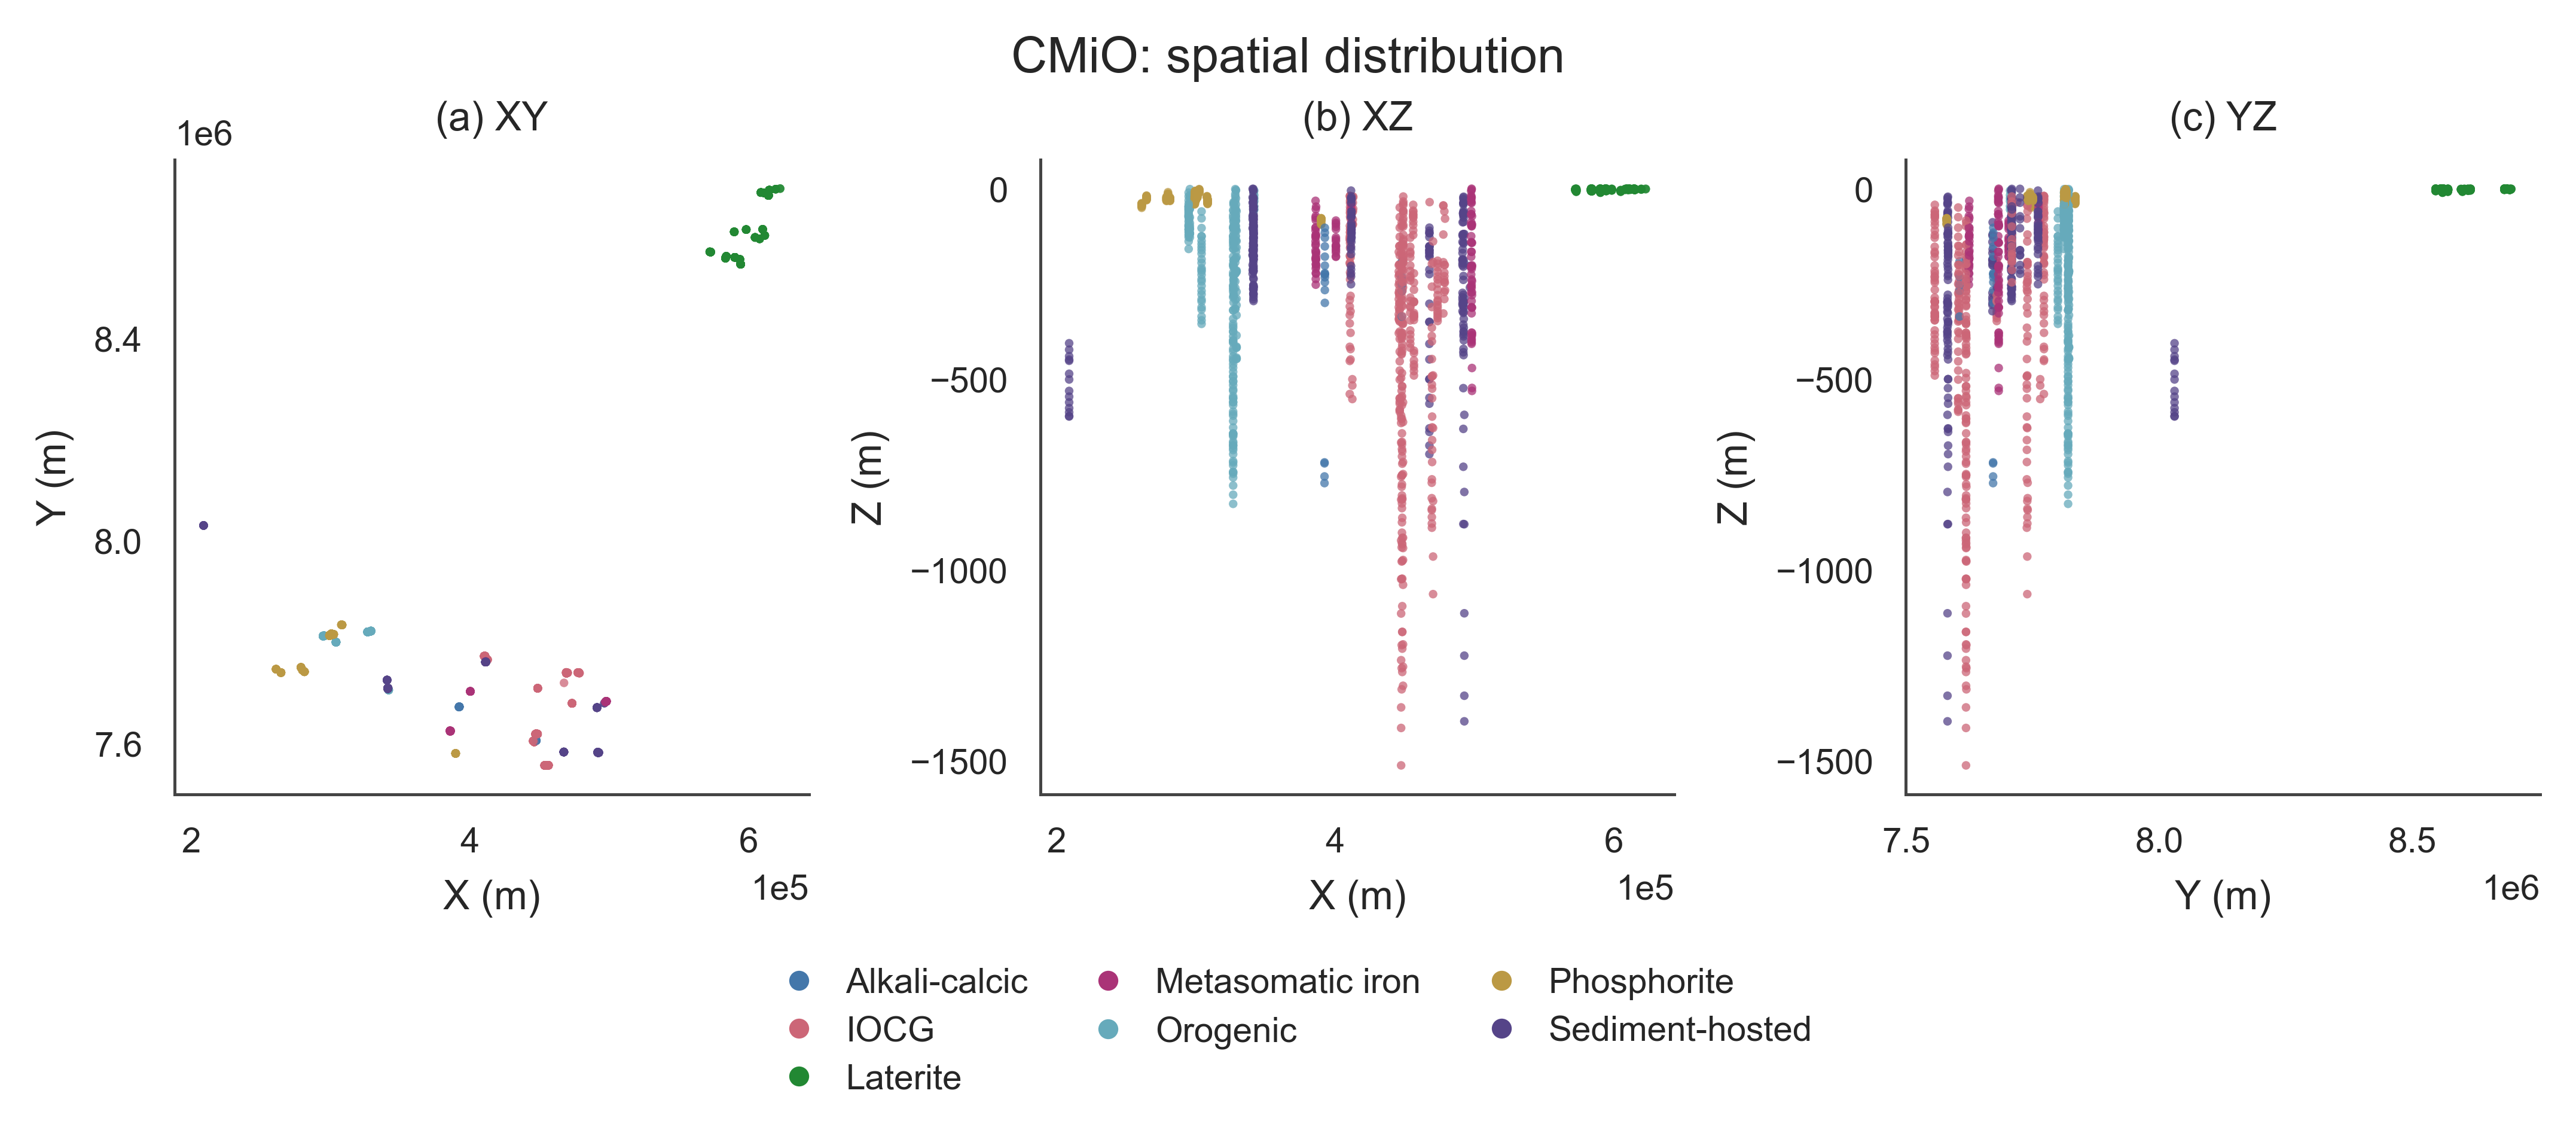

In [3]:
from IPython.display import display

display(data.groupby(['label_id','LABEL_deposit_group'], observed=True).size().rename('samples').reset_index())

fig, axes = plt.subplots(1, 3, figsize=(7.1, 3.05), layout='constrained')
for index, (ax, pair) in enumerate(zip(axes, [('x', 'y'), ('x', 'z'), ('y', 'z')])):
    points = ax.scatter(data[pair[0]], data[pair[1]], c=CLASS_INDEX,
                        cmap=CLASS_CMAP, norm=CLASS_NORM, s=3, alpha=.75, linewidths=0)
    ax.set(xlabel=f'{pair[0].upper()} (m)', ylabel=f'{pair[1].upper()} (m)',
           title=f'({chr(97 + index)}) {pair[0].upper()}{pair[1].upper()}')
    ax.set_box_aspect(1)
    ax.ticklabel_format(style='sci', axis='both', scilimits=(-3, 4), useOffset=False)
    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_locator(MaxNLocator(4))
class_legend(fig)
fig.suptitle(f'{DATASET_TITLE}: spatial distribution')
paper_show(fig)


## One seed: embeddings and K=7 evaluation

Each panel colors the raw 2-D embedding by the evaluation-only true label. K-means
still evaluates the same embedding at $K=7$ for the result table below. Cluster IDs
do not correspond between methods, and ground-truth labels are used only for plotting
and the ARI in the result table.

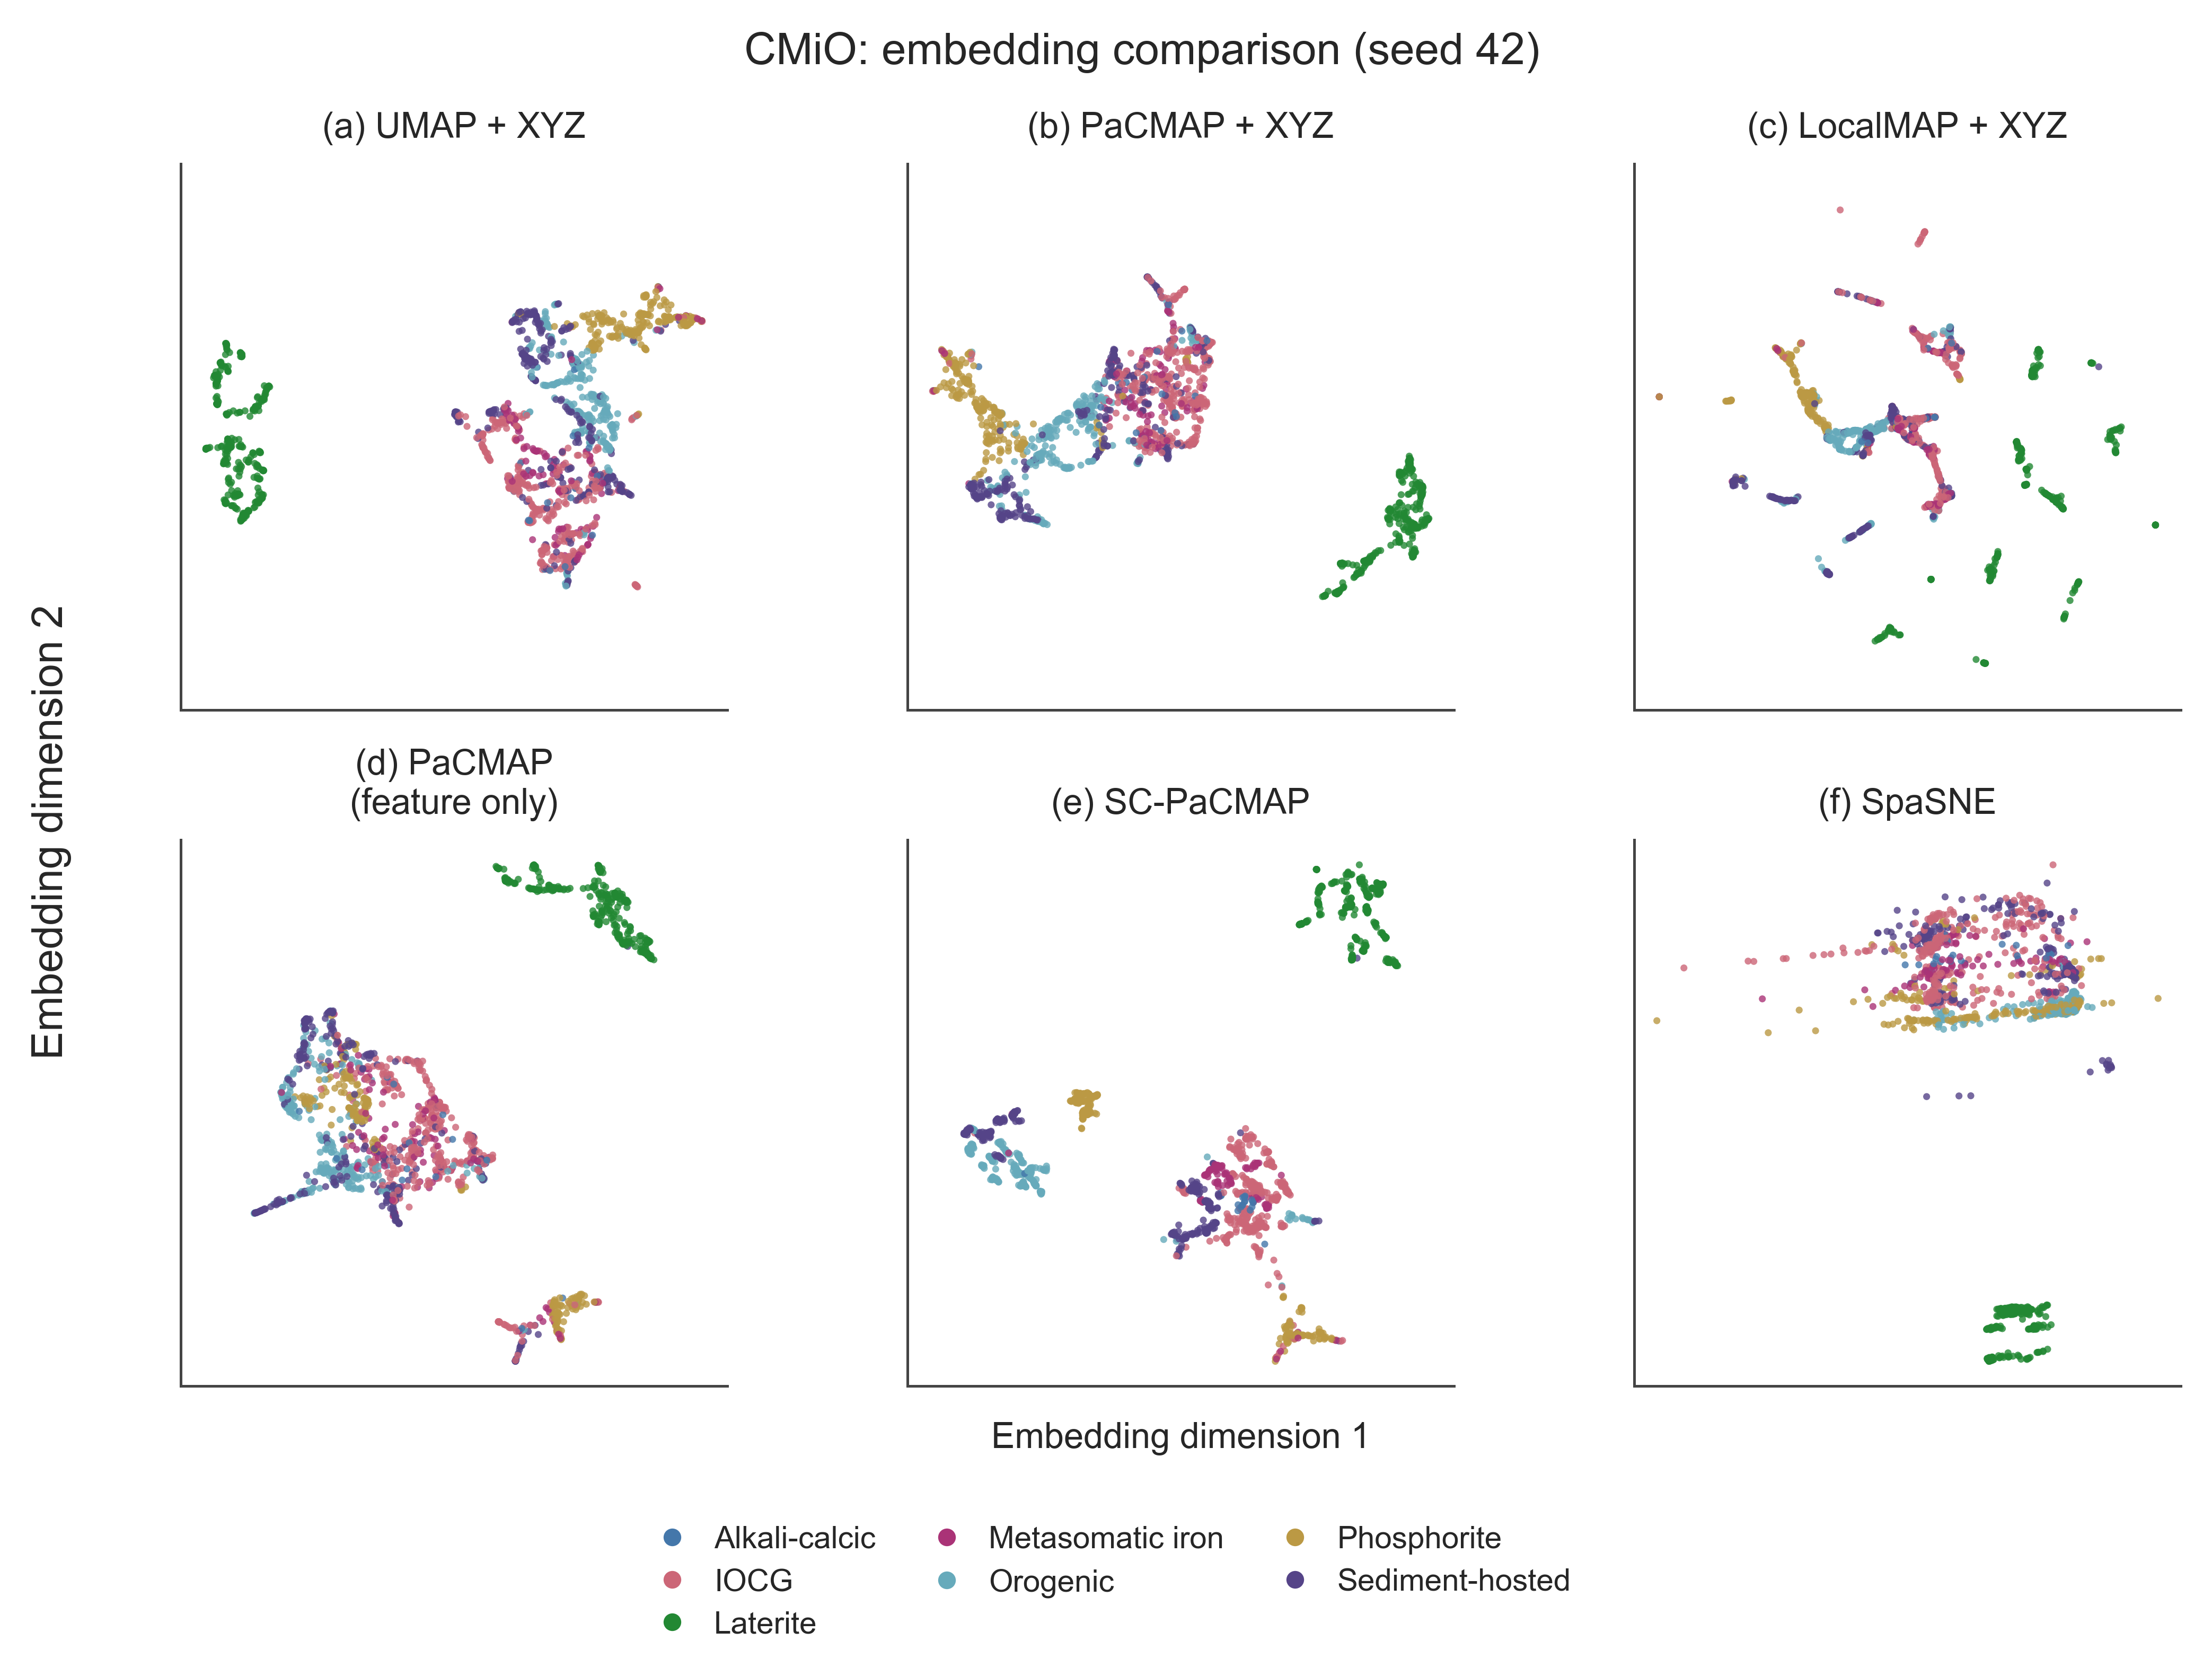

In [4]:

ncols = 3 if len(METHODS) <= 6 else 4
fig, axes = plt.subplots(2, ncols, figsize=(7.1, 5.15), layout='constrained')
for index, (ax, method) in enumerate(zip(axes.flat, METHODS)):
    embedding = one_seed_embeddings[method]
    points = ax.scatter(embedding[:, 0], embedding[:, 1], c=CLASS_INDEX,
                        cmap=CLASS_CMAP, norm=CLASS_NORM, s=2.5, alpha=.8, linewidths=0)
    short_title = METHOD_LABELS[method].replace(' feature-only', '\n(feature only)').replace(' replacement', '\n(replacement)').replace(' full graph', '\n(full graph)')
    ax.set_title(f'({chr(97 + index)}) {short_title}')
    ax.set_aspect('equal', adjustable='datalim')
    ax.set_box_aspect(1)
    # Embedding orientation and absolute coordinate values have no physical units.
    ax.set_xticks([])
    ax.set_yticks([])
for unused_ax in list(axes.flat)[len(METHODS):]:
    unused_ax.set_visible(False)
class_legend(fig)
# An axes label participates in layout above the external legend.
label_ax = axes[-1, (ncols - 1) // 2]
label_ax.set_xlabel('Embedding dimension 1', labelpad=8)
fig.supylabel('Embedding dimension 2')
fig.suptitle(f'{DATASET_TITLE}: embedding comparison (seed 42)')
paper_show(fig)


## Thirty-seed evaluation curves: neighborhood robustness

Embedding neighborhood sizes **10, 15, and 20** use the same **30 algorithm seeds (0?29)** on the same full dataset. The figure has one row per neighborhood size and one column per metric. Lines show seed medians; shading shows observed seed min?max ranges, not confidence intervals. Results are kept separate by neighborhood size, rather than pooled into a 90-run band.

Lowercase neighborhood size is distinct from **K**, the K-means cluster count swept along the horizontal axis. The reference line marks the dataset's true class count. K-means uses raw 2-D embeddings, 20 initializations, and a fixed clustering seed for each K. The geographic evaluation window remains **10 neighbors** in every panel so entropy measures the same spatial scale.

The neighborhood setting changes UMAP, PaCMAP, LocalMAP, and both SC-PaCMAP variants together. SpaSNE has no equivalent n_neighbors parameter: its perplexity stays at 50, and each seed's result is reused across rows as the same baseline. SC-PaCMAP uses max_target_share=1.0 throughout.

One-seed embeddings, lambda-cap sensitivity, and cross-group/deposit checks retain the default neighborhood size 10. This sweep tests sensitivity to neighborhood choice; it does not by itself guarantee stronger performance.

In the figure, rows identify embedding neighborhood size and columns identify metrics. Lower entropy and WCSS/TSS are better; higher ARI is better. Dotted lines mark the reference class count.


In [5]:
rows = []
for seed in SEEDS:
    # SpaSNE uses fixed perplexity=50, with no n_neighbors parameter.
    # Reuse that seed's baseline across neighborhood panels, not as independent runs.
    spasne_embedding = None
    for n_neighbors in NEIGHBOR_VALUES:
        embeddings, _ = fit_embeddings(seed, n_neighbors=n_neighbors,
                                       spasne_embedding=spasne_embedding)
        spasne_embedding = embeddings['SpaSNE']
        for method in METHODS:
            for k in K_VALUES:
                labels = KMeans(n_clusters=k, init='k-means++', n_init=20,
                                random_state=1000 + k).fit_predict(
                                    np.asarray(embeddings[method], dtype=np.float64))
                rows.append({'seed': seed, 'n_neighbors': n_neighbors,
                             'method': method, 'K': k, **evaluate(labels, k)})
        print(f'Completed algorithm seed {seed}, n_neighbors={n_neighbors}', flush=True)
results = pd.DataFrame(rows)
range_results = results
assert len(results) == len(SEEDS) * len(NEIGHBOR_VALUES) * len(METHODS) * len(K_VALUES)
assert not results.duplicated(['seed', 'n_neighbors', 'method', 'K']).any()
assert results.groupby(['n_neighbors', 'method', 'K']).seed.nunique().eq(len(SEEDS)).all()
assert np.isfinite(results[['H_per_sample', 'WCSS_TSS', 'ARI']].to_numpy()).all()



Completed algorithm seed 0, n_neighbors=10


Completed algorithm seed 0, n_neighbors=15


Completed algorithm seed 0, n_neighbors=20


Completed algorithm seed 1, n_neighbors=10


Completed algorithm seed 1, n_neighbors=15


...

Completed algorithm seed 28, n_neighbors=15


Completed algorithm seed 28, n_neighbors=20


Completed algorithm seed 29, n_neighbors=10


Completed algorithm seed 29, n_neighbors=15


Completed algorithm seed 29, n_neighbors=20


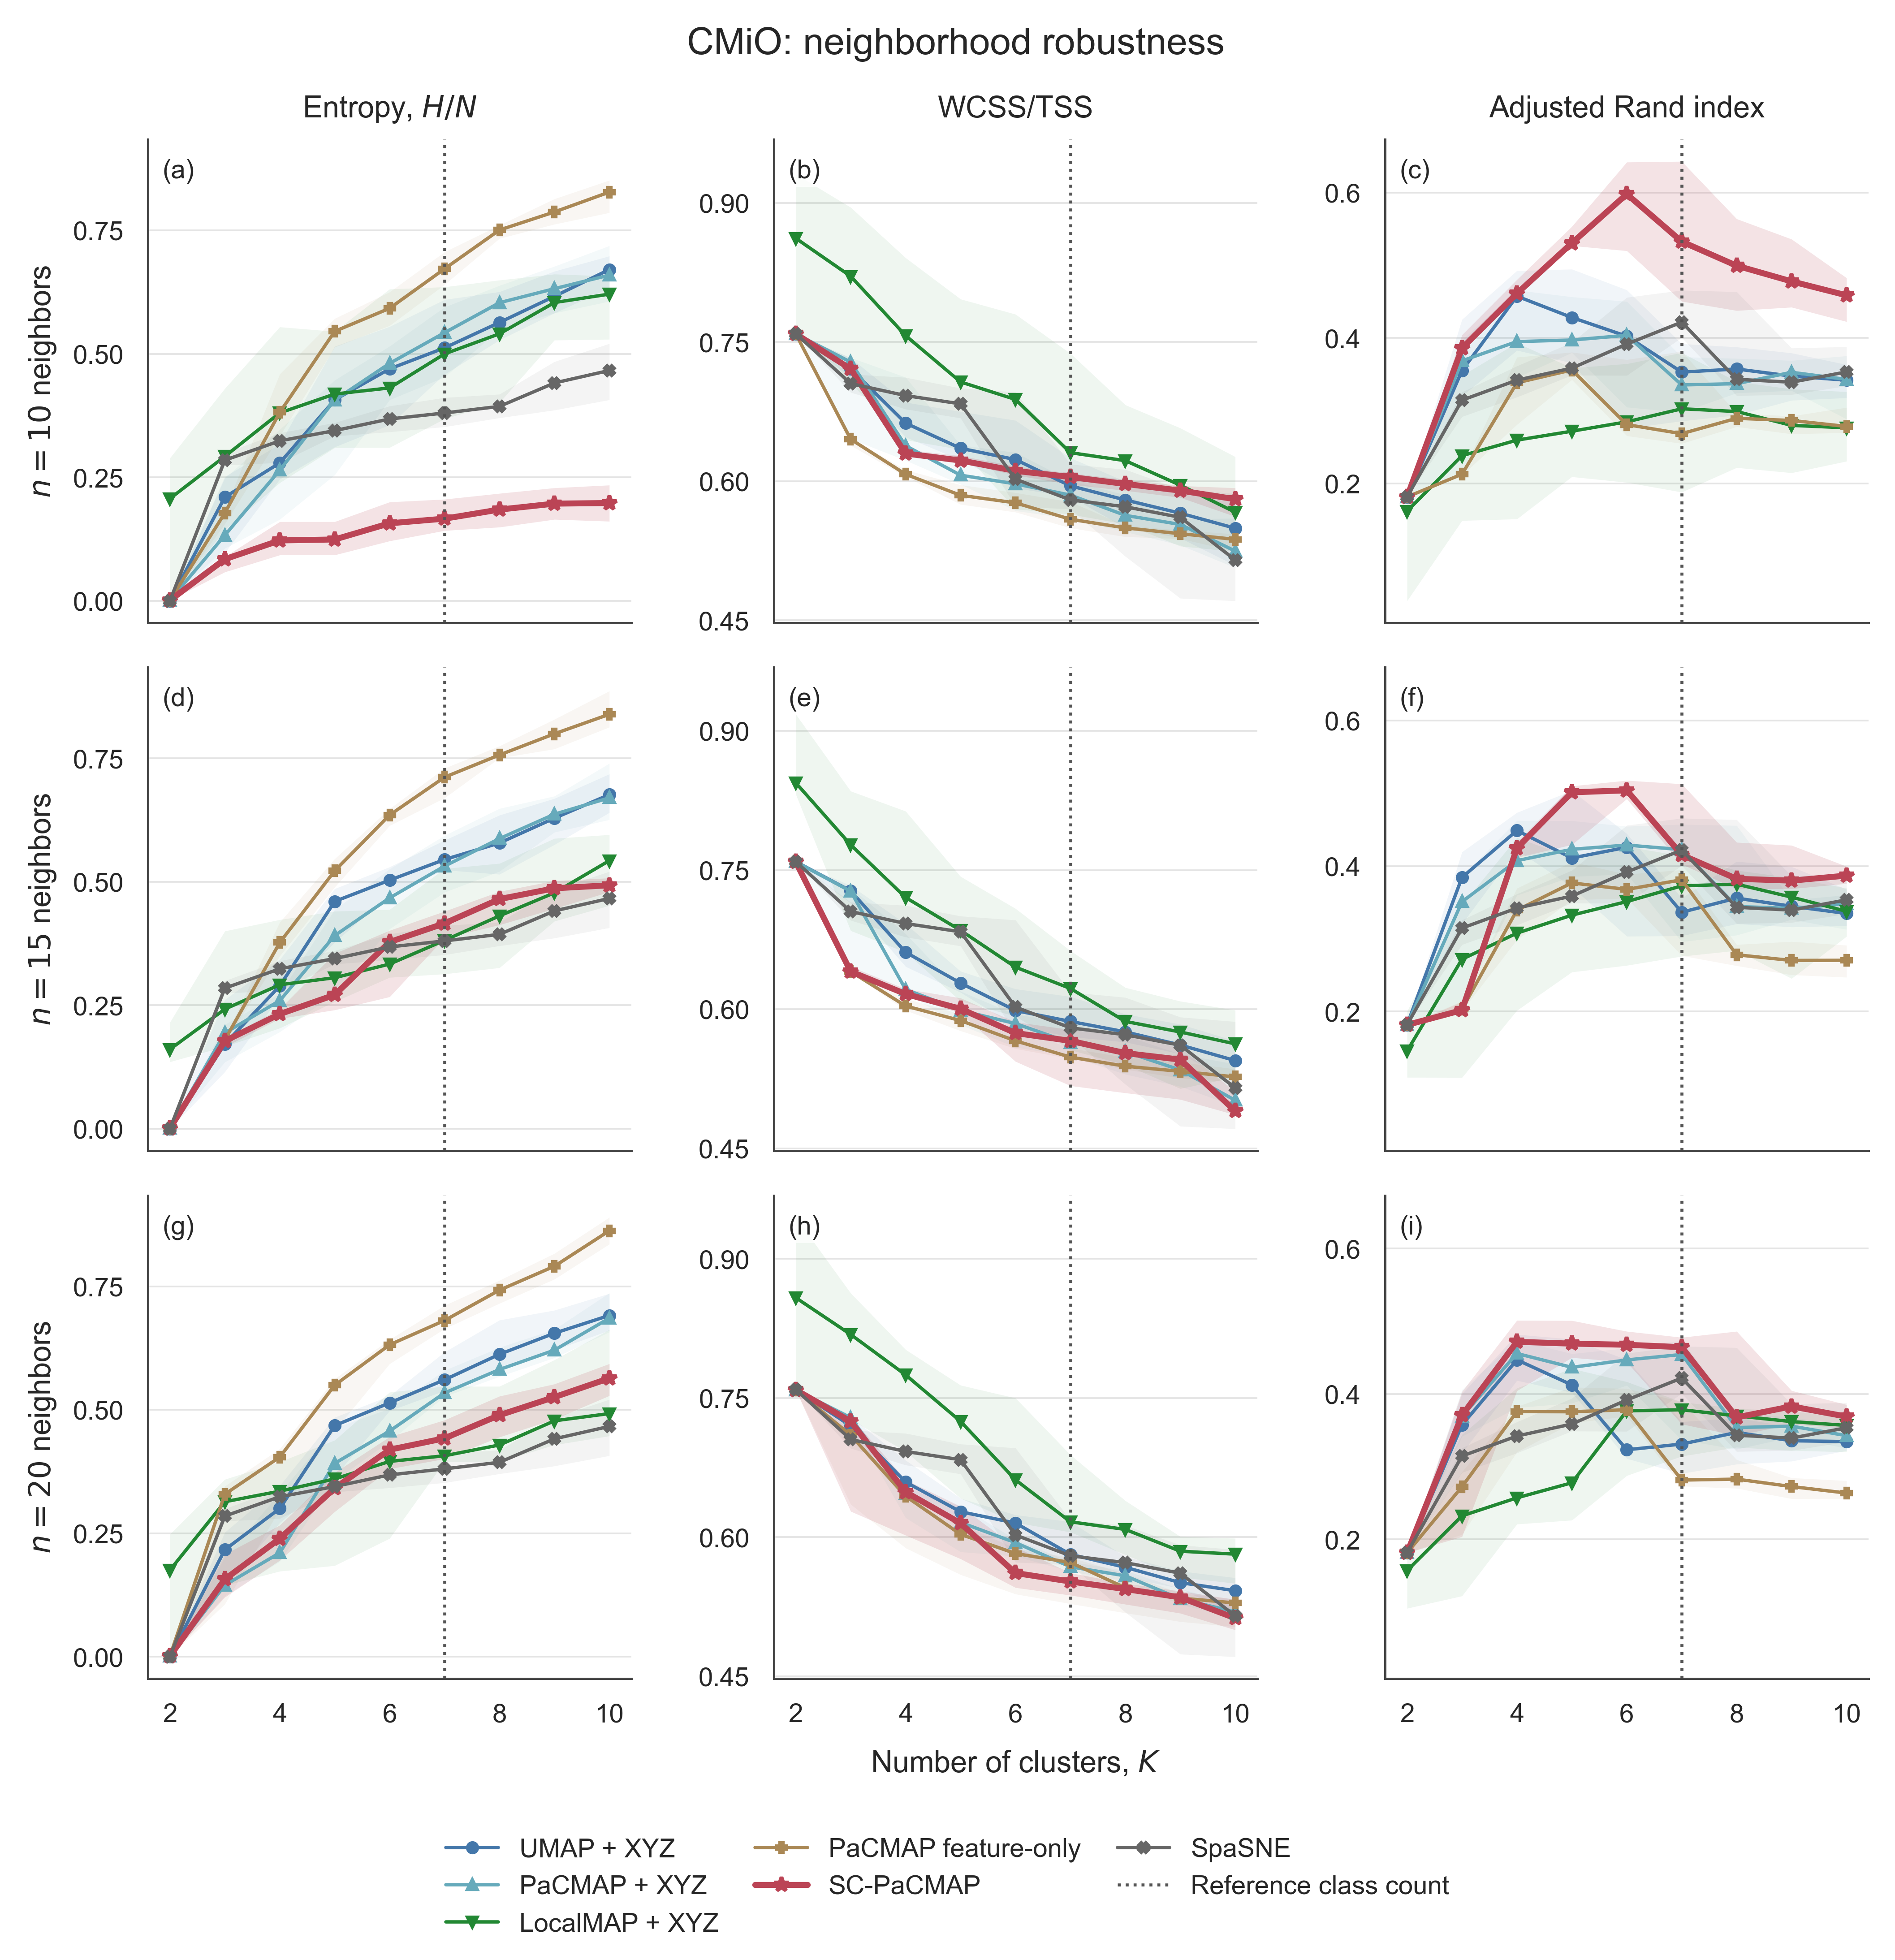

In [6]:

metric_specs = [('H_per_sample', r'Entropy, $H/N$'),
                ('WCSS_TSS', 'WCSS/TSS'), ('ARI', 'Adjusted Rand index')]
fig, axes = plt.subplots(len(NEIGHBOR_VALUES), 3, figsize=(7.1, 1.95 * len(NEIGHBOR_VALUES) + 1.35),
                         sharex=True, sharey='col', squeeze=False, layout='constrained')
for row, n_neighbors in enumerate(NEIGHBOR_VALUES):
    neighborhood_results = range_results[range_results.n_neighbors == n_neighbors]
    for col, (metric, metric_title) in enumerate(metric_specs):
        ax = axes[row, col]
        for method in METHODS:
            summary = neighborhood_results[neighborhood_results.method == method].groupby('K')[metric].agg(['median', 'min', 'max'])
            primary = method == 'SC-PaCMAP full graph'
            ax.fill_between(summary.index, summary['min'], summary['max'],
                            color=COLORS[method], alpha=.15 if primary else .07, linewidth=0)
            ax.plot(summary.index, summary['median'], color=COLORS[method], marker=MARKERS[method],
                    linewidth=1.6 if primary else .9, markersize=4 if primary else 2.5, label=METHOD_LABELS[method])
        ax.axvline(K_REFERENCE, color='#555555', ls=':', lw=.8)
        ax.set_box_aspect(1)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.grid(axis='y')
        if row == 0:
            ax.set_title(metric_title)
        if col == 0:
            ax.set_ylabel(f'$n={n_neighbors}$ neighbors')
        ax.text(.03, .96, f'({chr(97 + row * 3 + col)})', transform=ax.transAxes,
                va='top', fontsize=7, bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1))
axes[-1, 1].set_xlabel('Number of clusters, $K$', labelpad=6)
fig.suptitle(f'{DATASET_TITLE}: neighborhood robustness')
handles, labels = axes[0, 0].get_legend_handles_labels()
handles.append(Line2D([], [], color='#555555', ls=':', lw=.8))
labels.append('Reference class count')
fig.legend(handles, labels, loc='outside lower center', ncol=3, columnspacing=1.4, handlelength=2)
paper_show(fig)


## Three-metric results tables by map and neighbourhood size

Each row is one method and embedding neighbourhood **k** combination. The main
paper table fixes K-means cluster count **K** at the dataset's true class count.
All combinations are ranked by **mean spatial contiguity, highest first**.
Entries report **mean +/- sample standard deviation** across algorithm seeds.

All three scores are higher-is-better. Spatial contiguity (%) is
$100[1-(H/N)/\log K]$; multivariate delineation (%) is
$100(1-\mathrm{WCSS}/\mathrm{TSS})$. ARI retains its original scale.
Scores are transformed for each seed before summarizing. The spatial evaluation
window remains fixed at 10 neighbours. SD describes seed variability on this
fixed dataset, not uncertainty across datasets.

SpaSNE uses fixed perplexity 50 and appears **once per K**, with embedding k
marked "?". Its repeated baseline is not counted as additional seeds.
Expand the full-sweep table for all cluster counts, ranked separately within each K.
Unrounded summaries are retained in `metric_summary`; formatted tables are
`reference_metric_table` and `sweep_metric_table`. The three-metric line charts
continue to show H/N, WCSS/TSS, and ARI with seed medians and min-max ranges.


In [7]:
from IPython.display import HTML, display

summary_keys = ['method', 'n_neighbors', 'K']
summary_input = results.loc[
    results.method.isin(METHODS) & results.n_neighbors.isin(NEIGHBOR_VALUES)
].copy()
# SpaSNE is reused across neighbour settings: count each seed only once per K.
summary_input = summary_input.loc[
    (summary_input.method != 'SpaSNE')
    | (summary_input.n_neighbors == NEIGHBOR_VALUES[0])
].copy()
assert not summary_input.duplicated(summary_keys + ['seed']).any()
assert (summary_input.K > 1).all(), 'Normalized spatial contiguity requires K > 1.'
summary_input['spatial_contiguity'] = 100 * (
    1 - summary_input.H_per_sample / np.log(summary_input.K)
)
summary_input['multivariate_delineation'] = 100 * (1 - summary_input.WCSS_TSS)
summary_metrics = ['spatial_contiguity', 'multivariate_delineation', 'ARI']
summary_groups = summary_input.groupby(summary_keys, sort=False)
metric_summary = summary_groups[summary_metrics].agg(['mean', 'std'])
metric_summary.columns = [f'{metric}_{stat}' for metric, stat in metric_summary.columns]
metric_summary['n_seeds'] = summary_groups.seed.nunique()
metric_summary = metric_summary.reset_index()
metric_summary = metric_summary.sort_values(
    ['K', 'spatial_contiguity_mean', 'method', 'n_neighbors'],
    ascending=[True, False, True, True],
).reset_index(drop=True)
metric_summary.loc[metric_summary.method == 'SpaSNE', 'n_neighbors'] = np.nan

sweep_metric_table = metric_summary[summary_keys + ['n_seeds']].copy()
sweep_metric_table['n_neighbors'] = [
    '\u2014' if pd.isna(value) else str(int(value))
    for value in sweep_metric_table.n_neighbors
]
for metric, title, digits in [
    ('spatial_contiguity', 'Spatial contiguity (%) \u2191', 2),
    ('multivariate_delineation', 'Multivariate delineation (%) \u2191', 2),
    ('ARI', 'ARI \u2191', 4),
]:
    sweep_metric_table[title] = [
        f'{mean:.{digits}f} \u00b1 {std:.{digits}f}'
        for mean, std in zip(metric_summary[f'{metric}_mean'], metric_summary[f'{metric}_std'])
    ]
sweep_metric_table = sweep_metric_table.rename(columns={
    'method': 'Method', 'n_neighbors': 'Neighbour k', 'n_seeds': 'Seeds',
})
reference_metric_table = sweep_metric_table.loc[
    sweep_metric_table.K == K_REFERENCE
].drop(columns=['K']).reset_index(drop=True)
print(f'{DATASET_TITLE}: K={K_REFERENCE}; mean +/- sample SD across algorithm seeds')
display(HTML(reference_metric_table.to_html(index=False)))
display(HTML(
    '<details><summary>Full results table: all swept cluster counts K</summary>'
    + sweep_metric_table.to_html(index=False) + '</details>'
))


CMiO: K=7; mean +/- sample SD across algorithm seeds


Method,Neighbour k,Seeds,Spatial contiguity (%) ↑,Multivariate delineation (%) ↑,ARI ↑
SC-PaCMAP full graph,10,30,91.28 ± 0.88,39.53 ± 0.25,0.5312 ± 0.0506
SpaSNE,—,30,80.40 ± 0.95,41.29 ± 1.56,0.4294 ± 0.0235
LocalMAP + XYZ,15,30,79.65 ± 2.95,38.42 ± 2.62,0.3589 ± 0.0463
LocalMAP + XYZ,20,30,78.69 ± 1.45,38.21 ± 1.39,0.3750 ± 0.0155
SC-PaCMAP full graph,15,30,78.67 ± 0.55,43.35 ± 1.06,0.4185 ± 0.0190
SC-PaCMAP full graph,20,30,77.29 ± 0.91,44.97 ± 0.73,0.4383 ± 0.0431
LocalMAP + XYZ,10,30,74.29 ± 3.07,35.72 ± 4.29,0.2992 ± 0.0414
UMAP + XYZ,10,30,73.43 ± 1.49,40.16 ± 1.14,0.3488 ± 0.0222
PaCMAP + XYZ,15,30,72.64 ± 1.70,43.40 ± 1.21,0.4015 ± 0.0542
PaCMAP + XYZ,10,30,72.40 ± 1.84,41.51 ± 0.89,0.3358 ± 0.0188


Method,Neighbour k,K,Seeds,Spatial contiguity (%) ↑,Multivariate delineation (%) ↑,ARI ↑
SpaSNE,—,2,30,100.00 ± 0.00,24.10 ± 0.00,0.1817 ± 0.0000
UMAP + XYZ,10,2,30,100.00 ± 0.00,24.10 ± 0.00,0.1817 ± 0.0000
UMAP + XYZ,15,2,30,100.00 ± 0.00,24.10 ± 0.00,0.1817 ± 0.0000
UMAP + XYZ,20,2,30,100.00 ± 0.00,24.10 ± 0.00,0.1817 ± 0.0000
PaCMAP + XYZ,10,2,30,99.85 ± 0.00,24.12 ± 0.00,0.1815 ± 0.0000
PaCMAP + XYZ,15,2,30,99.85 ± 0.00,24.12 ± 0.00,0.1815 ± 0.0000
PaCMAP + XYZ,20,2,30,99.85 ± 0.00,24.12 ± 0.00,0.1815 ± 0.0000
PaCMAP feature-only,10,2,30,99.85 ± 0.00,24.12 ± 0.00,0.1815 ± 0.0000
PaCMAP feature-only,15,2,30,99.85 ± 0.00,24.12 ± 0.00,0.1815 ± 0.0000
PaCMAP feature-only,20,2,30,99.85 ± 0.00,24.12 ± 0.00,0.1815 ± 0.0000


## Combined trade-off cloud at the true class count

One plot combines all seed results at **K=K_REFERENCE**. **Color identifies the method; shape identifies embedding neighborhood size:** circles for 10, triangles for 15, and squares for 20. Each neighborhood-dependent method contributes **90 small transparent points** (30 paired seeds ? three settings). SpaSNE contributes **30 diamond points**, shown once because its fixed-perplexity results are reused across neighborhood settings.

Large outlined markers show the median for each method?neighborhood combination; set `SHOW_CLOUD_MEDIANS=False` to display only the seed points. The geographic evaluation window stays fixed at 10 neighbors. Lower-left is better jointly; these points show paired algorithm runs, not independent datasets.

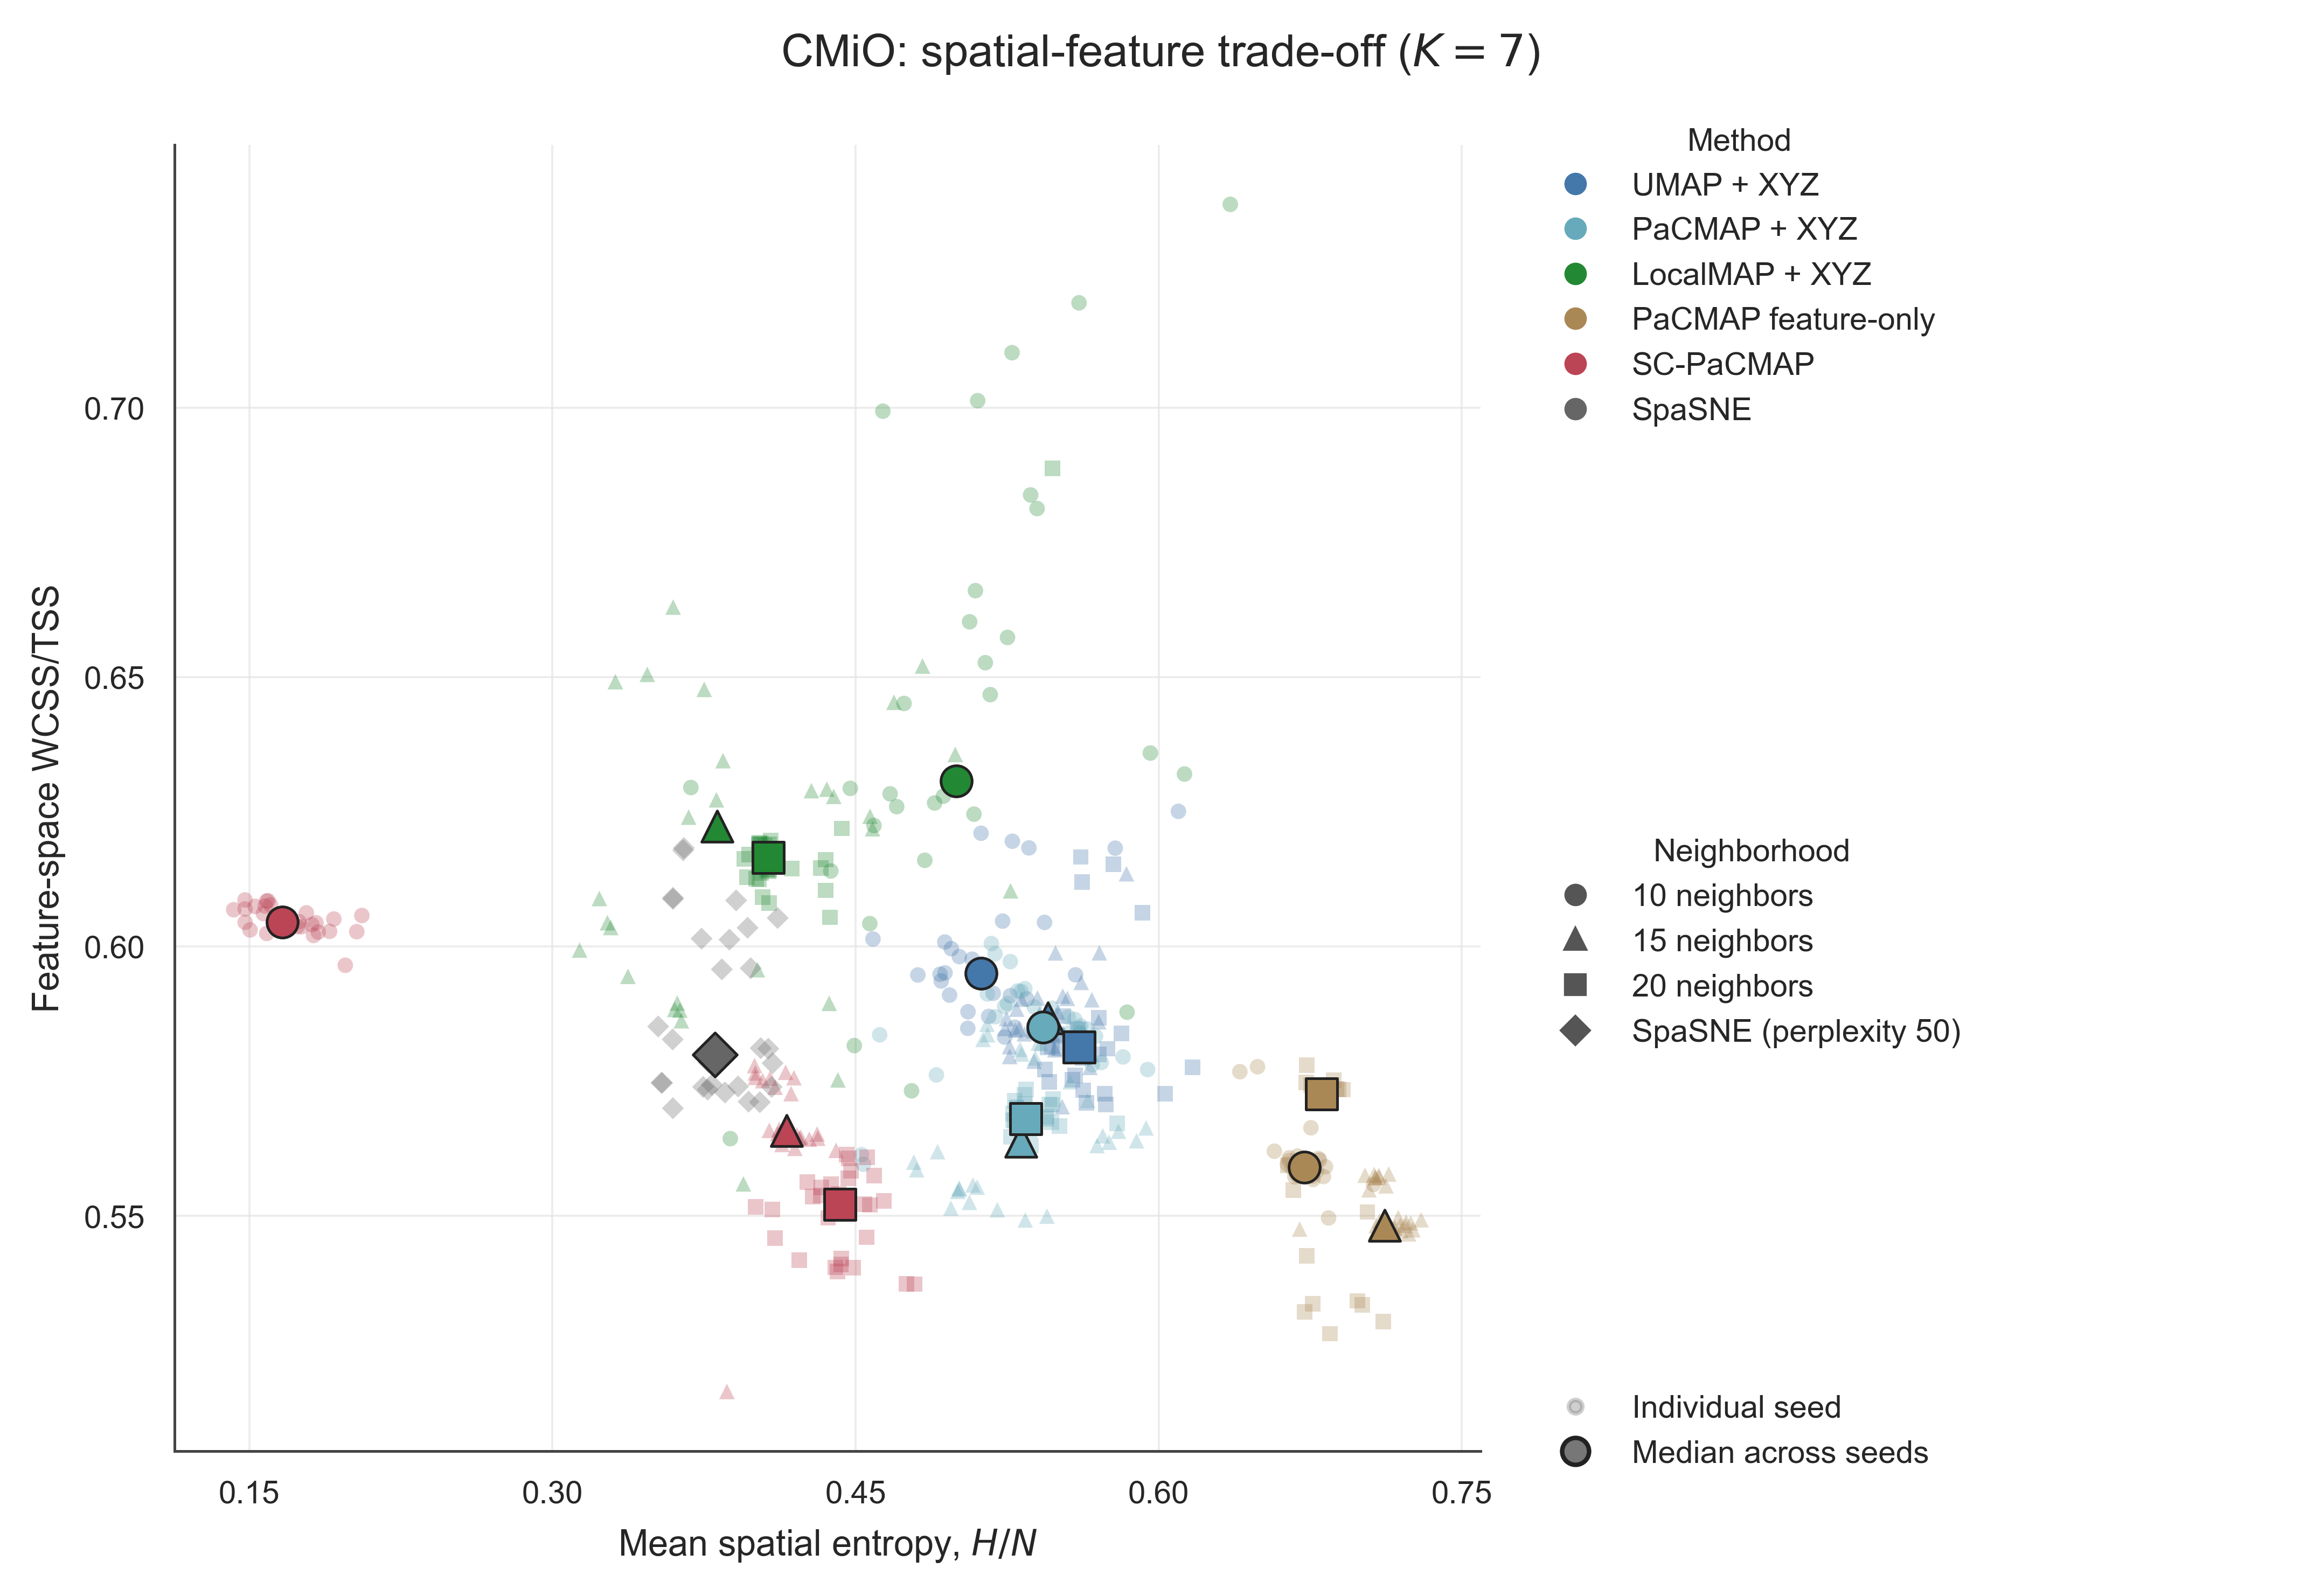

In [8]:

from matplotlib.lines import Line2D
cloud = results[(results.K == K_REFERENCE) & results.method.isin(METHODS) & results.n_neighbors.isin(NEIGHBOR_VALUES)].copy()
# SpaSNE's fixed-perplexity run is shown once per seed.
cloud = cloud[(cloud.method != 'SpaSNE') | (cloud.n_neighbors == NEIGHBOR_VALUES[0])]
cloud_medians = cloud.groupby(['n_neighbors', 'method'])[['H_per_sample', 'WCSS_TSS']].median()
NEIGHBOR_MARKERS = {10: 'o', 15: '^', 20: 's'}
SHOW_CLOUD_MEDIANS = True
fig = plt.figure(figsize=(7.1, 4.8), layout='constrained')
grid = fig.add_gridspec(1, 2, width_ratios=[1, .58])
ax = fig.add_subplot(grid[0, 0])
legend_ax = fig.add_subplot(grid[0, 1])
legend_ax.set_axis_off()
for method in METHODS:
    neighbor_settings = (NEIGHBOR_VALUES[0],) if method == 'SpaSNE' else NEIGHBOR_VALUES
    for n_neighbors in neighbor_settings:
        part = cloud[(cloud.method == method) & (cloud.n_neighbors == n_neighbors)]
        marker = 'D' if method == 'SpaSNE' else NEIGHBOR_MARKERS[n_neighbors]
        ax.scatter(part.H_per_sample, part.WCSS_TSS, color=COLORS[method],
                   marker=marker, s=12, alpha=.3, edgecolors='none')
        if SHOW_CLOUD_MEDIANS:
            median = cloud_medians.loc[(n_neighbors, method)]
            ax.scatter(median.H_per_sample, median.WCSS_TSS, color=COLORS[method],
                       marker=marker, s=48, edgecolor='#222222', linewidth=.6, zorder=4)
ax.set(xlabel=r'Mean spatial entropy, $H/N$', ylabel='Feature-space WCSS/TSS')
ax.set_box_aspect(1)
ax.grid(alpha=.7)
ax.xaxis.set_major_locator(MaxNLocator(5))
ax.yaxis.set_major_locator(MaxNLocator(5))
method_handles = [Line2D([], [], color=COLORS[m], marker='o', linestyle='None', markersize=4, label=METHOD_LABELS[m]) for m in METHODS]
method_legend = legend_ax.legend(handles=method_handles, title='Method', loc='upper left',
                                  bbox_to_anchor=(0, 1), borderaxespad=0)
legend_ax.add_artist(method_legend)
neighbor_handles = [Line2D([], [], color='#555555', marker=NEIGHBOR_MARKERS[n], linestyle='None',
                           markersize=4, label=f'{n} neighbors') for n in NEIGHBOR_VALUES]
neighbor_handles.append(Line2D([], [], color='#555555', marker='D', linestyle='None',
                               markersize=4, label='SpaSNE (perplexity 50)'))
neighbor_legend = legend_ax.legend(handles=neighbor_handles, title='Neighborhood', loc='upper left',
                                    bbox_to_anchor=(0, .48), borderaxespad=0)
legend_ax.add_artist(neighbor_legend)
point_handles = [Line2D([], [], color='#777777', marker='o', linestyle='None', alpha=.35, markersize=3, label='Individual seed')]
if SHOW_CLOUD_MEDIANS:
    point_handles.append(Line2D([], [], color='#777777', marker='o', markeredgecolor='#222222',
                                linestyle='None', markersize=6, label='Median across seeds'))
legend_ax.legend(handles=point_handles, loc='lower left', bbox_to_anchor=(0, 0), borderaxespad=0)
fig.suptitle(f'{DATASET_TITLE}: spatial-feature trade-off ($K={K_REFERENCE}$)')
paper_show(fig)


## Lambda-cap sensitivity at $K=7$

Ten algorithm seeds sweep `SCPaCMAPConfig(max_target_share=...)` on the fixed
full dataset. This parameter caps both the automatically inferred lambda used
in the share calculation and the final Phase-3 spatial-attraction share; it does
not replace lambda with a manually fixed value. The benchmark uses max_target_share=1.0: no extra clipping below the natural bound of 1. The sweep includes that baseline.
The dashed line marks the data-derived automatic lambda for reference.

Lines show seed medians; shading shows min-max seed ranges. Here the two evaluation
scores are percentages (higher is better): spatial contiguity is
$100(1-(H/N)/\log K)$ and multivariate delineation is $100(1-\mathrm{WCSS}/\mathrm{TSS})$.

The dashed automatic-lambda marker is a reference on the cap axis; cap 1 is the unrestricted adaptive run.


In [9]:
lambda_caps = np.linspace(0., 1.0, 10)  # Include the no-extra-clipping baseline.
lambda_rows = []
for seed in SENSITIVITY_SEEDS:
    settings = PaCMAPSettings(random_state=seed, **settings_base)
    for cap in lambda_caps:
        result, diag = run_sc_pacmap(features, coords, settings,
                                    config=SCPaCMAPConfig(max_target_share=float(cap)))
        labels = KMeans(n_clusters=K_REFERENCE, init='k-means++', n_init=20,
                        random_state=1000 + K_REFERENCE).fit_predict(result.embedding)
        metrics = evaluate(labels, K_REFERENCE)
        lambda_rows.append({'seed': seed, 'lambda_cap': cap,
                            'automatic_lambda': diag.spatial_strength_lambda,
                            'target_share': diag.automatic_target_share,
                            'spatial': 100 * (1 - metrics['H_per_sample'] / np.log(K_REFERENCE)),
                            'multivariate': 100 * (1 - metrics['WCSS_TSS'])})
    print(f'Completed sensitivity seed {seed}', flush=True)
lambda_results = pd.DataFrame(lambda_rows)


Completed sensitivity seed 0
Completed sensitivity seed 1
Completed sensitivity seed 2
Completed sensitivity seed 3
Completed sensitivity seed 4
Completed sensitivity seed 5
Completed sensitivity seed 6
Completed sensitivity seed 7
Completed sensitivity seed 8
Completed sensitivity seed 9


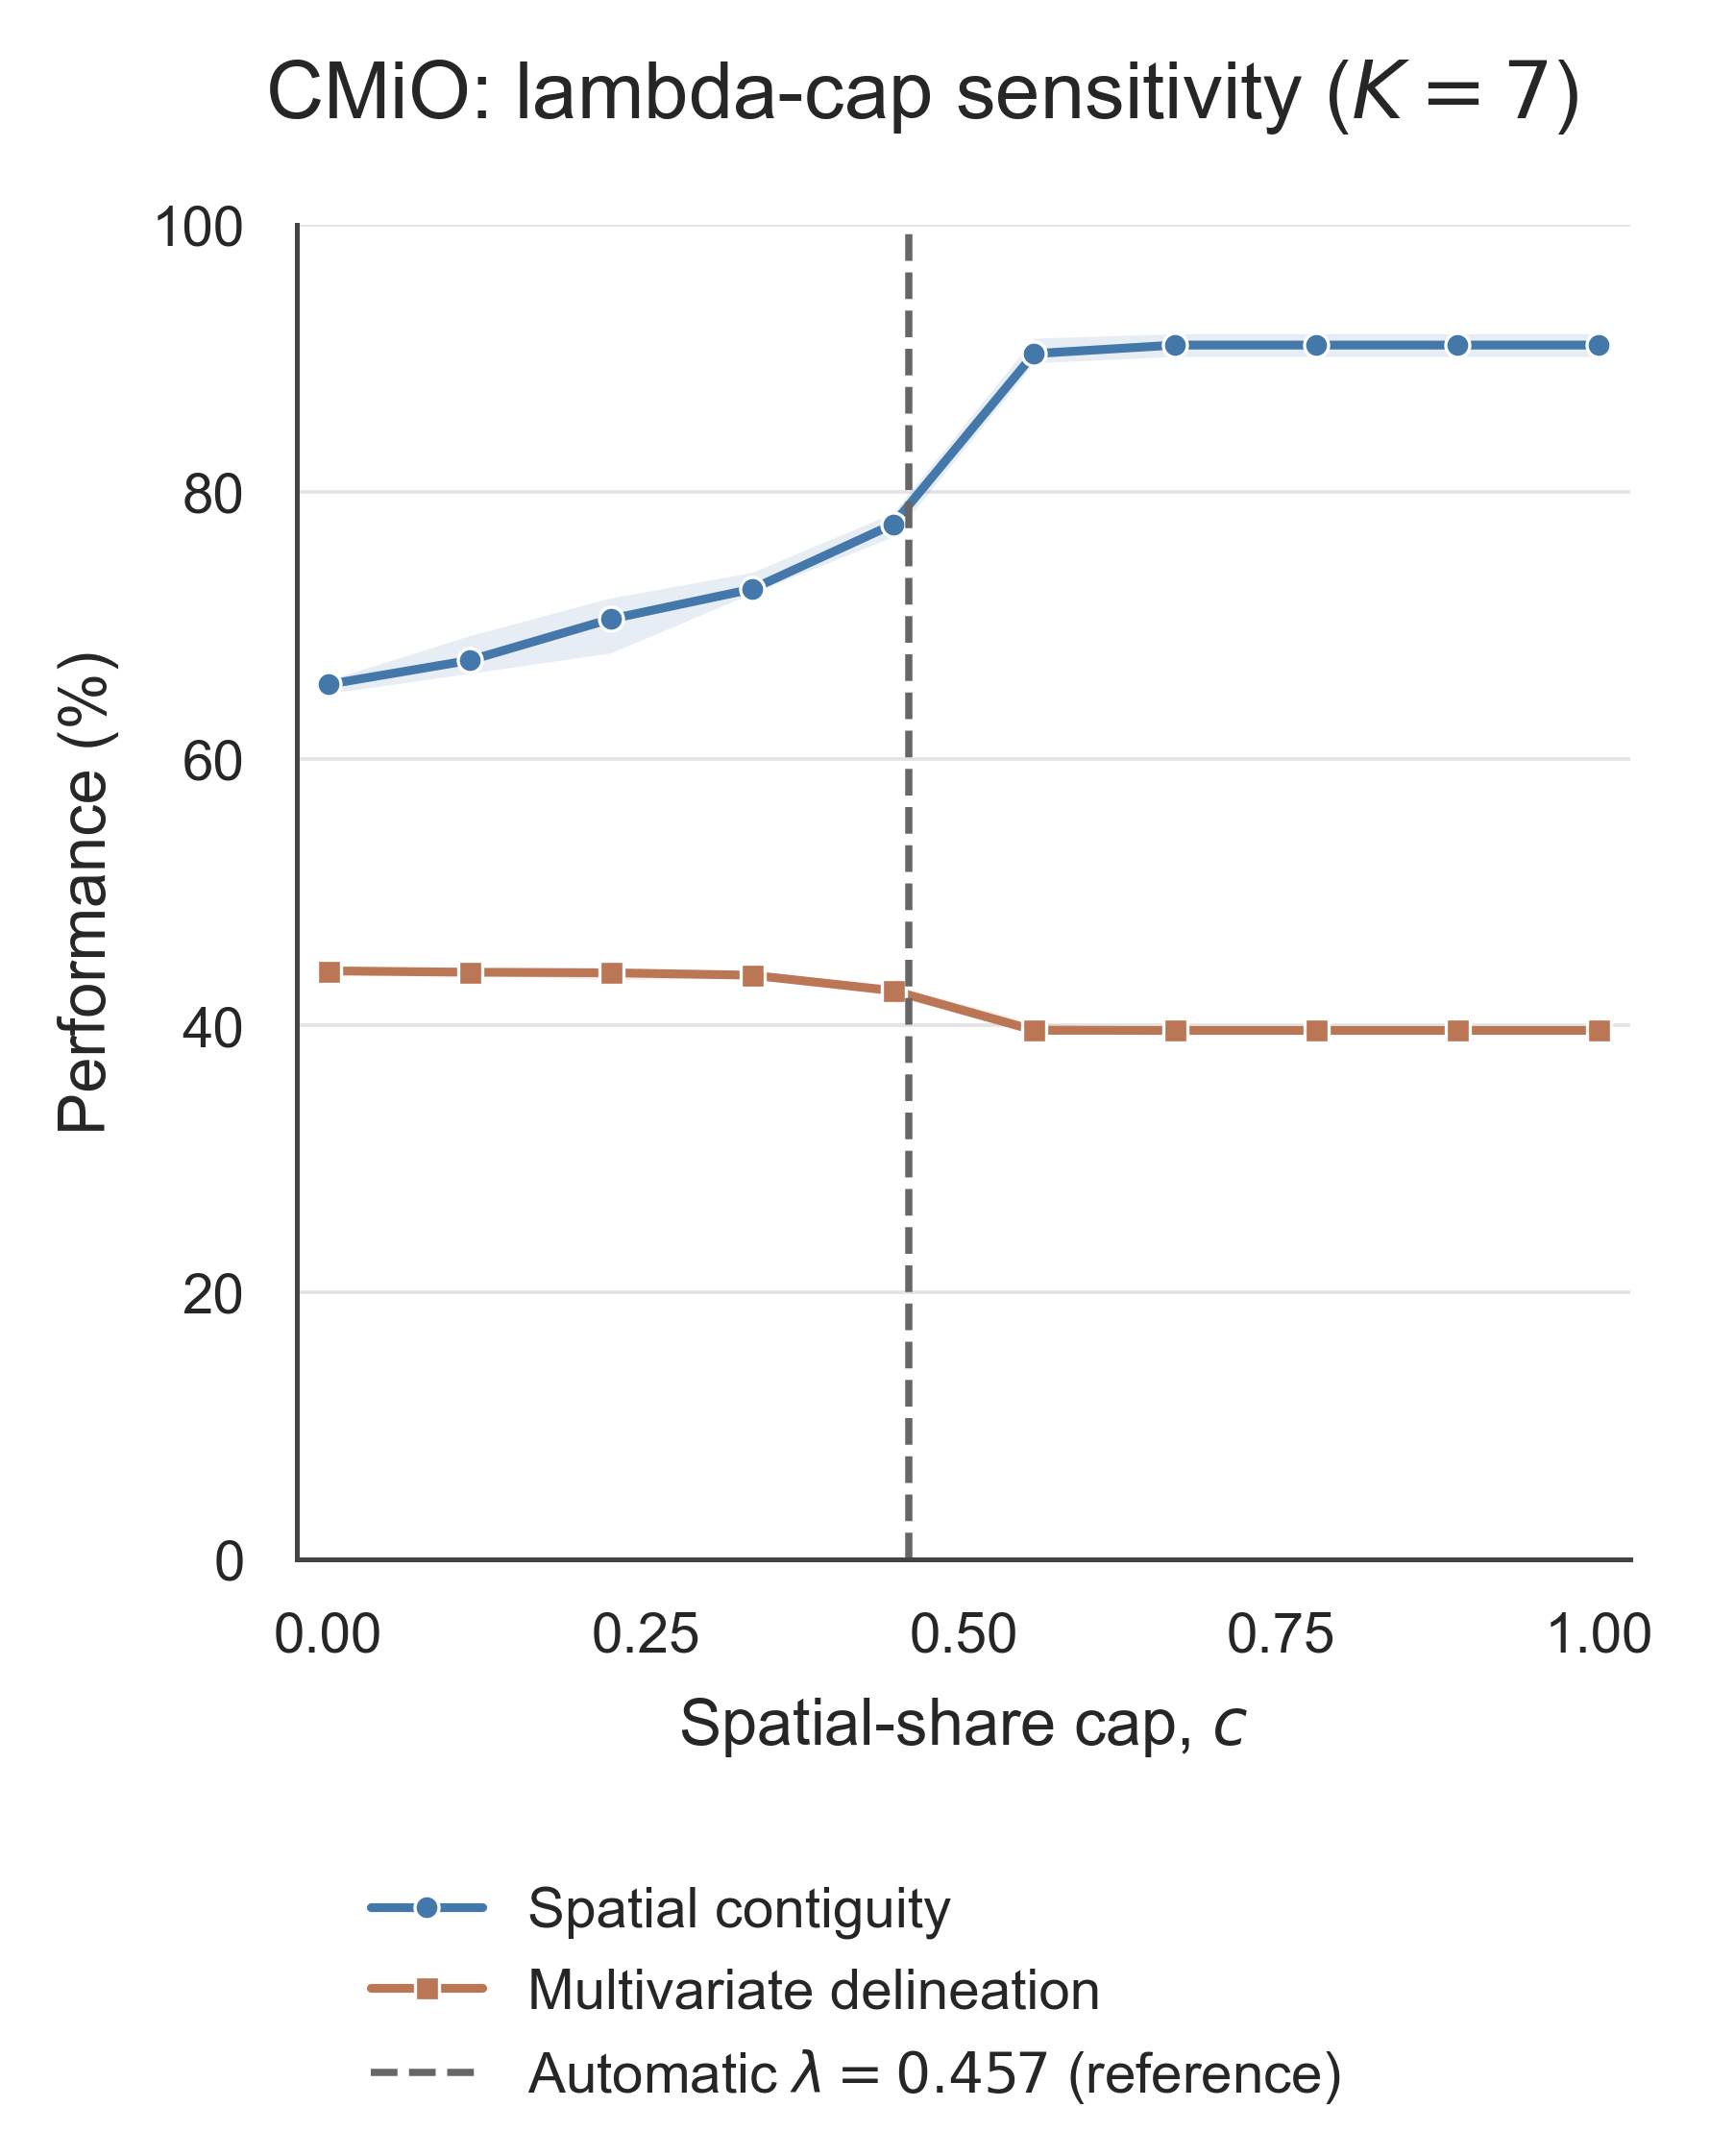

In [10]:

automatic_lambda = float(lambda_results.automatic_lambda.median())
fig, ax = plt.subplots(figsize=(3.5, 3.65), layout='constrained')
for metric, label, color, marker in [
    ('spatial', 'Spatial contiguity', '#4477AA', 'o'),
    ('multivariate', 'Multivariate delineation', '#BB7755', 's'),
]:
    summary = lambda_results.groupby('lambda_cap')[metric].agg(['median', 'min', 'max'])
    ax.fill_between(summary.index, summary['min'], summary['max'], color=color, alpha=.13, linewidth=0)
    ax.plot(summary.index, summary['median'], color=color, marker=marker, markersize=3,
            markeredgecolor='white', markeredgewidth=.4, label=label)
ax.axvline(automatic_lambda, color='#666666', ls='--', lw=.9,
           label=rf'Automatic $\lambda={automatic_lambda:.3f}$ (reference)')
ax.set(xlabel=r'Spatial-share cap, $c$', ylabel='Performance (%)',
       xlim=(-.025, 1.025), ylim=(0, 100), xticks=[0, .25, .5, .75, 1])
ax.set_box_aspect(1)
ax.grid(axis='y')
fig.suptitle(f'{DATASET_TITLE}: lambda-cap sensitivity ($K={K_REFERENCE}$)')
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=1)
paper_show(fig)


## Deposit confounding: graph composition and cross-group continuity

**Methodology.** For each directed graph, the within-deposit fraction is the number of edges whose endpoints share `group_id`, divided by the total number of edges. CMiO uses individual deposit names, not deposit-type labels; North Batten uses drillhole IDs. We report the ordinary geochemical neighbour graph ($G_G$), the selected spatial constraint graph ($G_S$), and the geographic candidate graph separately. Fractions are unweighted edge counts, including spatial edges overlapping the geochemical graph, at the reference setting (seed 42, 10 neighbours); an empty graph has an undefined fraction.

To assess whether spatial continuity extends beyond within-deposit smoothing, we select each sample's 10 nearest spatial neighbours **after excluding all samples from its own deposit**. Across 10 algorithm seeds (0?9), we report continuity as $100[1-\overline{H}/\log K]$, where $H$ is the entropy of cluster memberships among the eligible neighbours and $K$ is the reference cluster count. Higher values mean more homogeneous neighbouring cluster memberships. The focal sample is excluded. These are diagnostics on full-data fitted embeddings, not held-out-group predictions; homogeneous neighbours need not share the focal sample's cluster. Paired seed differences and Holm-adjusted Wilcoxon tests compare SC-PaCMAP with the baselines; seed ranges describe algorithm variability, not independent geological replication.

ARI provides supporting agreement with evaluation labels only and is not evidence of multivariate delineation. Interpret cross-group continuity alongside geochemical WCSS/TSS. A gain beyond local smoothing must be supported by the cross-group results rather than inferred from the within-group fractions alone.


In [11]:
from IPython.display import display
from sc_pacmap import original as graph_backend

group_values = data['group_id'].to_numpy()
assert not pd.isna(group_values).any(), 'Group IDs are required for every sample.'
_, geographic_candidates, _ = graph_backend.compute_nearest_neighbors(
    np.ascontiguousarray(coords, dtype=np.float32), N_NEIGHBORS,
    'euclidean', settings_base['knn_backend'], 42,
)
graph_rows = []
for graph_name, neighbors in [
    ('G_G: ordinary geochemical', one_seed_diag.ordinary_neighbors),
    ('G_S: selected spatial constraints', one_seed_diag.selected_spatial_neighbors),
    ('Geographic candidates', geographic_candidates),
]:
    neighbors = np.asarray(neighbors, dtype=int)
    same = group_values[:, None] == group_values[neighbors]
    graph_rows.append({
        'graph': graph_name, 'directed_edges': int(same.size),
        'within_group_edges': int(same.sum()),
        'cross_group_edges': int(same.size - same.sum()),
        'within_group_fraction': float(same.mean()) if same.size else np.nan,
    })
graph_confounding = pd.DataFrame(graph_rows)
display(graph_confounding.round(4))


,graph,directed_edges,within_group_edges,cross_group_edges,within_group_fraction
0,G_G: ordinary geochemical,15510,7419,8091,0.4783
1,G_S: selected spatial constraints,7755,7691,64,0.9917
2,Geographic candidates,15510,15350,160,0.9897


### Cross-deposit continuity results

The following stored results use the exclusion and entropy definition above. Run this section to refresh the ten-seed comparison.


In [12]:
from scipy.stats import wilcoxon


def paired_wilcoxon_table(frame, value_column, primary_method='SC-PaCMAP full graph'):
    rows = []
    comparator_methods = [method for method in METHODS if method != primary_method]
    for comparator in comparator_methods:
        paired = frame.pivot(index='seed', columns='method', values=value_column).dropna()
        differences = paired[primary_method] - paired[comparator]
        if np.allclose(differences, 0.0):
            statistic, p_value = 0.0, 1.0
        else:
            test = wilcoxon(
                differences,
                alternative='greater',
                zero_method='wilcox',
                method='auto',
            )
            statistic, p_value = float(test.statistic), float(test.pvalue)
        rows.append({
            'primary': primary_method,
            'comparator': comparator,
            'paired_seeds': len(differences),
            'median_difference': float(np.median(differences)),
            'primary_wins': int(np.sum(differences > 0)),
            'ties': int(np.sum(differences == 0)),
            'wilcoxon_statistic': statistic,
            'p_greater': p_value,
        })
    results = pd.DataFrame(rows).sort_values('p_greater').reset_index(drop=True)
    running_maximum = 0.0
    adjusted = []
    for rank, p_value in enumerate(results['p_greater']):
        corrected = min(1.0, p_value * (len(results) - rank))
        running_maximum = max(running_maximum, corrected)
        adjusted.append(running_maximum)
    results['holm_p'] = adjusted
    return results


def cross_group_neighbors(coordinates, groups, n=N_NEIGHBORS):
    distances = ((coordinates[:, None, :] - coordinates[None, :, :]) ** 2).sum(2)
    distances[groups[:, None] == groups[None, :]] = np.inf
    np.fill_diagonal(distances, np.inf)
    if np.any(np.isfinite(distances).sum(axis=1) < n):
        raise ValueError('Fewer than n eligible cross-group neighbours for at least one sample.')
    return np.argsort(distances, axis=1)[:, :n]

cross_neighbors = cross_group_neighbors(coords, data.group_id.astype(str).to_numpy())
holdout_rows = []
for seed in SENSITIVITY_SEEDS:
    embeddings, _ = fit_embeddings(seed)
    for method in METHODS:
        labels = KMeans(
            n_clusters=K_REFERENCE,
            n_init=20,
            random_state=1000 + K_REFERENCE,
        ).fit_predict(embeddings[method])
        holdout_rows.append({
            'seed': seed,
            'method': method,
            'cross_group_spatial': 100 * (
                1 - entropy(labels, cross_neighbors) / np.log(K_REFERENCE)
            ),
        })

holdout = pd.DataFrame(holdout_rows)
display(
    holdout.groupby('method').cross_group_spatial
    .agg(['median', 'min', 'max'])
    .round(2)
)



cross_group_tests = paired_wilcoxon_table(holdout, 'cross_group_spatial')
display(cross_group_tests.round(4))
print(
    'One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has '
    'higher cross-group continuity than each comparator; Holm-adjusted alpha = 0.05.'
)
print(
    'Statistically higher than every comparator:',
    bool((cross_group_tests['holm_p'] < 0.05).all()),
)

,median,min,max
method,,,
LocalMAP + XYZ,68.65,66.64,75.81
PaCMAP + XYZ,67.75,63.84,72.99
PaCMAP feature-only,67.01,64.28,68.15
SC-PaCMAP full graph,93.88,89.82,96.00
SpaSNE,81.87,75.71,84.34
UMAP + XYZ,72.15,67.79,75.59


,primary,comparator,paired_seeds,median_difference,primary_wins,ties,wilcoxon_statistic,p_greater,holm_p
0,SC-PaCMAP full graph,UMAP + XYZ,10,21.5283,10,0,55.0,0.001,0.0049
1,SC-PaCMAP full graph,PaCMAP + XYZ,10,24.5766,10,0,55.0,0.001,0.0049
2,SC-PaCMAP full graph,LocalMAP + XYZ,10,23.0059,10,0,55.0,0.001,0.0049
3,SC-PaCMAP full graph,PaCMAP feature-only,10,26.7320,10,0,55.0,0.001,0.0049
4,SC-PaCMAP full graph,SpaSNE,10,11.7262,10,0,55.0,0.001,0.0049


One-sided paired Wilcoxon tests whether SC-PaCMAP full graph has higher cross-group continuity than each comparator; Holm-adjusted alpha = 0.05.
Statistically higher than every comparator: True


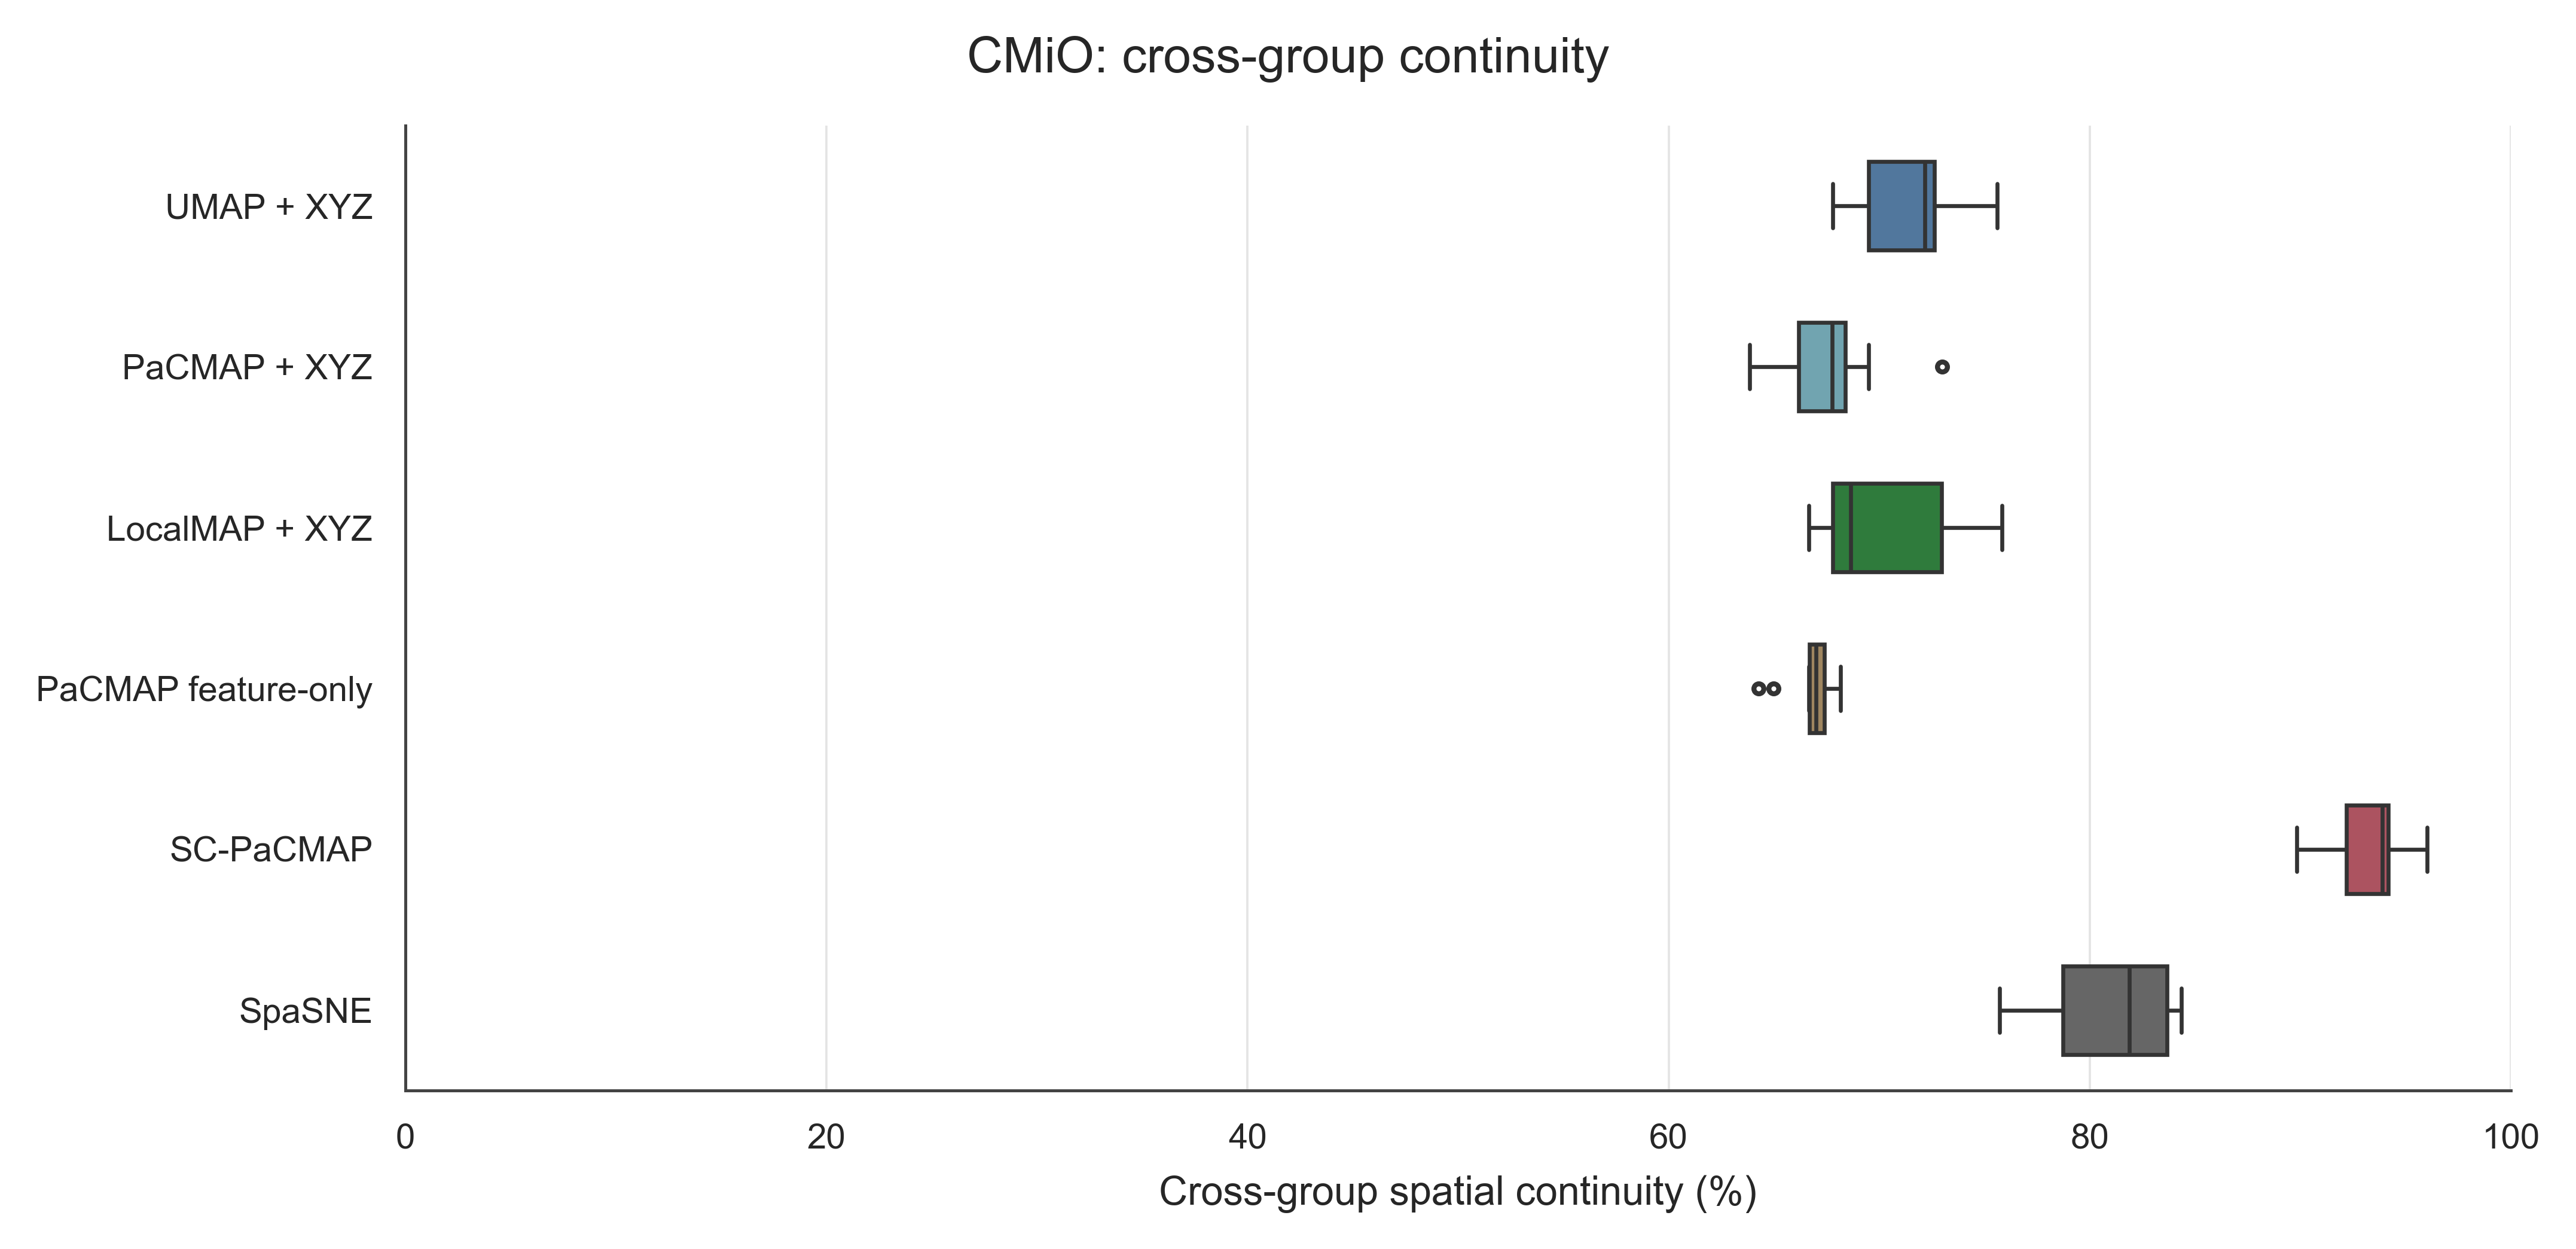

In [13]:
fig, ax = plt.subplots(figsize=(7.1, 3.4), layout='constrained')
sns.boxplot(data=holdout, x='cross_group_spatial', y='method', hue='method', order=METHODS,
            hue_order=METHODS, palette=COLORS, legend=False, width=.55,
            linewidth=.8, fliersize=2, ax=ax)
ax.set(xlabel='Cross-group spatial continuity (%)', ylabel='', xlim=(0, 100))
ax.set_yticks(range(len(METHODS)), [METHOD_LABELS[m] for m in METHODS])
ax.grid(axis='x')
fig.suptitle(f'{DATASET_TITLE}: cross-group continuity')
paper_show(fig)
